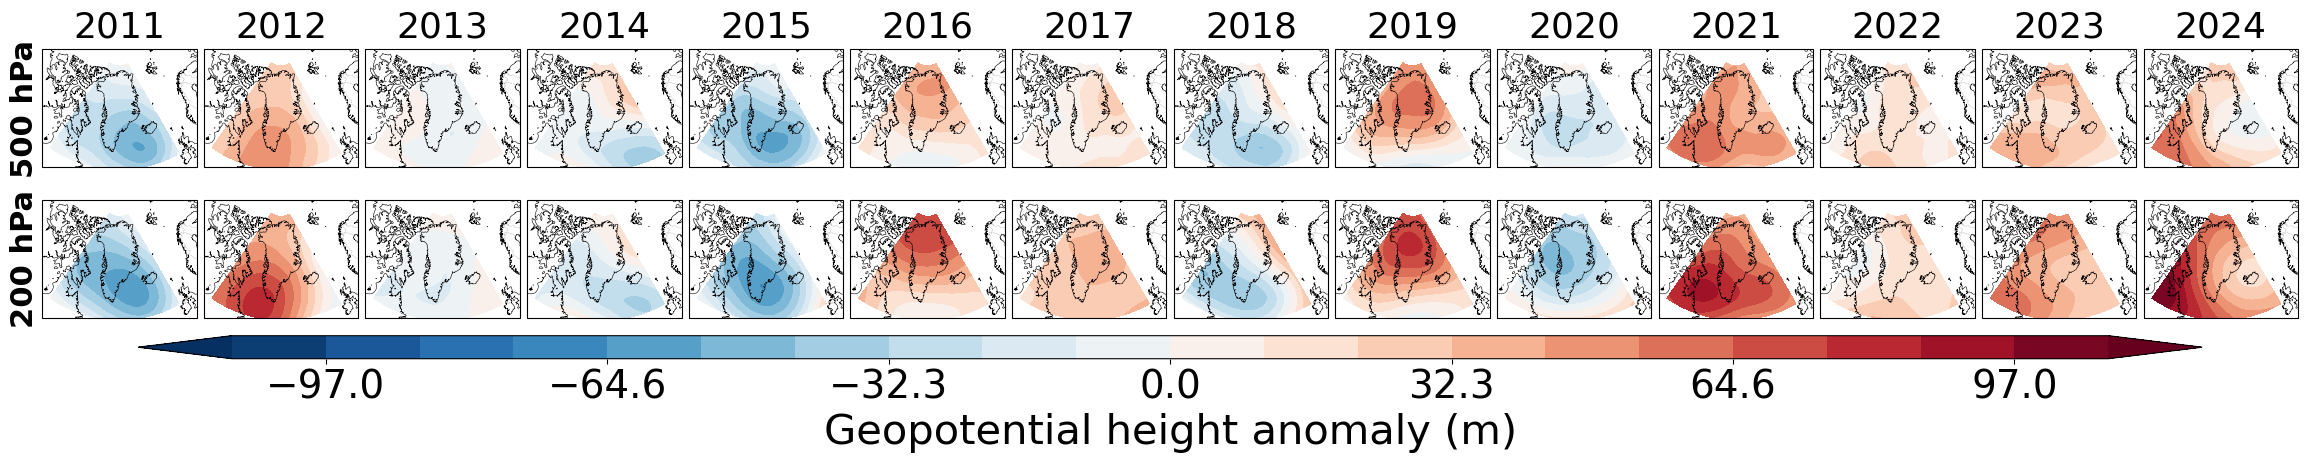

In [15]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ================= 尺寸总控（你只改这里） =================
FONT_SIZE       = 30   # 全局字号（色标、年份刻度等）
ROW_LABEL_SIZE  = 22   # 行标字号：500 hPa / 200 hPa   ← 你要的
YEAR_FONT_SIZE  = 26   # 年份标签字号
# ========================================================

# ========== 1) 数据 ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5pressure500&200pha.nc"
try:
    ds = xr.open_dataset(file_path)
    z500 = ds["z"].sel(pressure_level=500) / 9.80665
    z200 = ds["z"].sel(pressure_level=200) / 9.80665
except FileNotFoundError:
    lons = np.arange(-180, 180, 5)
    lats = np.arange(55, 95, 2.5)
    times = [f"{y}-07-15" for y in range(2011, 2025)]
    mock = np.random.randn(len(times), len(lats), len(lons)) * 10
    z500 = xr.DataArray(mock, coords=[times, lats, lons], dims=["valid_time","latitude","longitude"])
    z200 = xr.DataArray(mock*1.5, coords=[times, lats, lons], dims=["valid_time","latitude","longitude"])

def anomalies_vs_clim(z_data, plot_years):
    clim = z_data.mean("valid_time")
    anos = {}
    for y in plot_years:
        try:
            jja = z_data.sel(valid_time=z_data["valid_time"].dt.year == y).mean("valid_time")
        except Exception:
            jja = z_data.sel(valid_time=z_data["valid_time"].astype(str).str.startswith(str(y))).mean("valid_time")
        anos[y] = jja - clim
    amax = max(max(abs(anos[y].max().values), abs(anos[y].min().values)) for y in plot_years)
    return anos, amax

years = list(range(2011, 2025))
ano500, amax500 = anomalies_vs_clim(z500, years)
ano200, amax200 = anomalies_vs_clim(z200, years)
ABS_MAX = max(amax500, amax200)

# ========== 2) 画图（手动轴布局，行距=子图高度10%） ==========
proj = ccrs.NorthPolarStereo(central_longitude=-40)
fig = plt.figure(figsize=(24, 7.2))

left, right = 0.03, 0.97
top, bottom = 0.90, 0.10

N = len(years)
gap_w = 0.003
row_height = 0.19
gap_v_ratio = 0.10
gap_v = row_height * gap_v_ratio

total_w = right - left
axes_w = (total_w - gap_w * (N - 1)) / N

y_top = top - row_height
y_bottom = y_top - gap_v - row_height

# 上排 500 hPa
axes_top = []
for i, y in enumerate(years):
    x0 = left + i * (axes_w + gap_w)
    ax = fig.add_axes([x0, y_top, axes_w, row_height], projection=proj)
    axes_top.append(ax)
    ax.set_extent([-80, 0, 55, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.2)
    ax.set_xticks([]); ax.set_yticks([])
    cf = ax.contourf(
        ano500[y].longitude, ano500[y].latitude, ano500[y],
        levels=np.linspace(-ABS_MAX, ABS_MAX, 21),
        cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree()
    )

axes_top[0].text(-0.02, 0.5, "500 hPa", transform=axes_top[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE, weight='bold', rotation=90)

# 下排 200 hPa
axes_bot = []
for i, y in enumerate(years):
    x0 = left + i * (axes_w + gap_w)
    ax = fig.add_axes([x0, y_bottom, axes_w, row_height], projection=proj)
    axes_bot.append(ax)
    ax.set_extent([-80, 0, 55, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.2)
    ax.set_xticks([]); ax.set_yticks([])
    cf = ax.contourf(
        ano200[y].longitude, ano200[y].latitude, ano200[y],
        levels=np.linspace(-ABS_MAX, ABS_MAX, 21),
        cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree()
    )

axes_bot[0].text(-0.02, 0.5, "200 hPa", transform=axes_bot[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE, weight='bold', rotation=90)

# 年份标签（紧贴上排）
for i, y in enumerate(years):
    bb = axes_top[i].get_position()
    fig.text(bb.x0 + bb.width/2, bb.y1 + 0.008, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

# 共用色条（紧贴下排）
cbar_h = 0.032
cbar_y = y_bottom - 0.012 - cbar_h
cax = fig.add_axes([left + 0.04, cbar_y, (right - left) - 0.08, cbar_h])
cbar = fig.colorbar(cf, cax=cax, orientation="horizontal")
cbar.set_label("Geopotential height anomaly (m)", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-2)

plt.show()


✅ Data range: 1950–2024 (75 years)


C:\Users\11823\AppData\Local\Temp\ipykernel_13508\3220741145.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


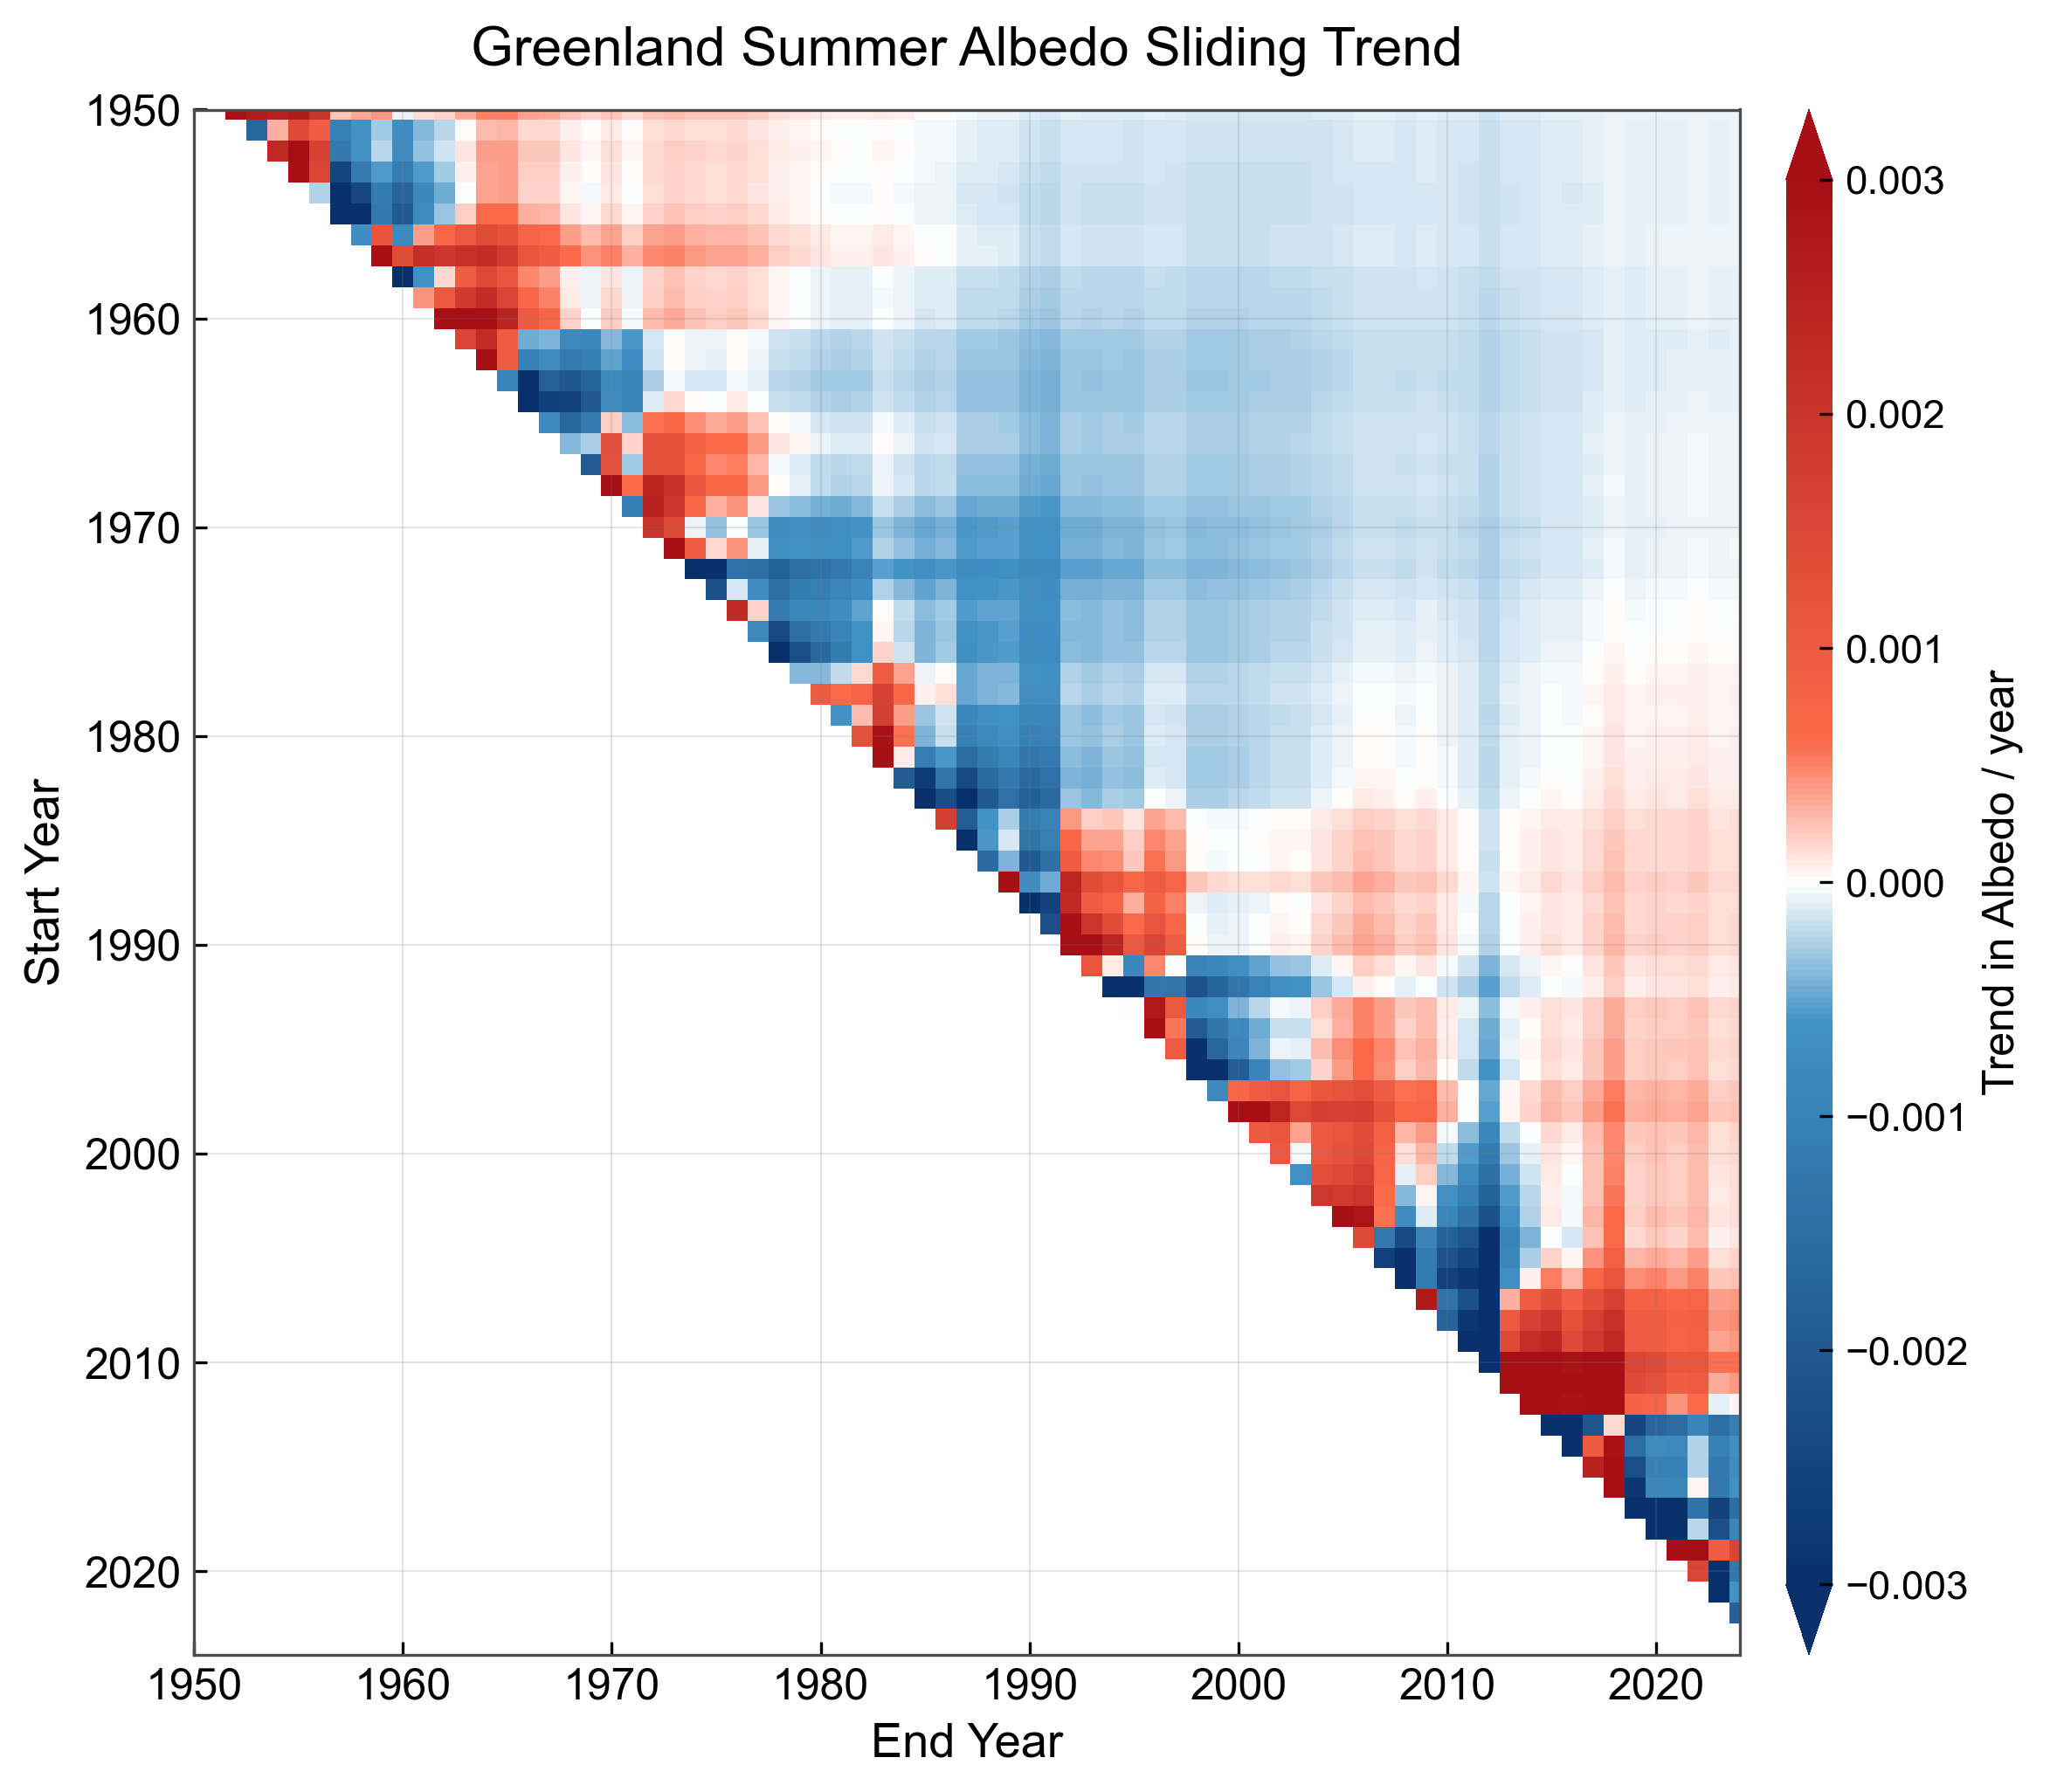

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 (Path - 请根据你的实际路径修改) =====
# 注意：你需要确保这个文件路径是正确的，并且文件存在
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
# 假设文件路径存在且数据结构正确
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含“albedo”的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 核心修改：计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 自定义色图（蓝-白-红，用于趋势） =====
# 这种色图非常适合 Nature 家族期刊风格，清晰地展示了正负趋势。
colors = [
    (0.00, "#08306b"),  # Darkest Blue
    (0.40, "#4292c6"),  # Light Blue
    (0.50, "#ffffff"),  # White Center (0)
    (0.60, "#fb6a4a"),  # Light Red
    (1.00, "#a50f15")   # Darkest Red
]
cmap = LinearSegmentedColormap.from_list("bluewhite_red_trend", colors, N=256)

# ===== 5. 绘图样式参数设置 =====
# 字体设置，推荐使用 Arial 或 Times New Roman 等通用字体
FONT_SIZE = 12 
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in", # 刻度线向内
    "ytick.direction": "in", # 刻度线向内
})

# ===== 6. 绘图 =====
# 调整 figsize 让图表看起来更宽敞
fig, ax = plt.subplots(figsize=(8.0, 7.0), dpi=300) 

# 设置颜色条的范围和中心点（对称色条的规范做法）
vmin, vmax = -0.003, 0.003
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

# 绘制热力图。由于 trend_matrix[i, j] 存储的是 i: Start Year, j: End Year，
# 且 Y 轴反转，所以数据显示在右上角。
pcm = ax.pcolormesh(years, years, trend_matrix,
                    cmap=cmap, norm=norm,
                    shading="auto", rasterized=True)

# ===== 7. 坐标与方向控制与刻度设置 =====
ax.set_xlim(years.min(), years.max())
# 关键：设置 Y 轴从上到下 (1950 在顶部)，与右图一致
ax.set_ylim(years.max(), years.min()) 
ax.set_aspect("equal")
ax.set_facecolor("white") # 背景色保持白色

ax.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 3, pad=12)

# 设置主要刻度（每隔10年）
tick_years = np.arange(years.min(), years.max() + 1, 10)
ax.set_xticks(tick_years)
ax.set_yticks(tick_years)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

# ===== 8. 色条（右侧对齐，等高） =====
# 使用 inset_axes 精确控制色条位置和大小
cax = inset_axes(ax, width="3%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
                 bbox_transform=ax.transAxes, borderpad=0)
# extend="both" 表示色条两端有三角，用于超范围的值
cbar = plt.colorbar(pcm, cax=cax, extend="both", 
                    ticks=np.linspace(vmin, vmax, 7)) # 增加刻度数量，更精细
cbar.set_label("Trend in Albedo / year", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-1)
cbar.outline.set_visible(False) # 移除边框，更简洁

# ===== 9. 网格与版面 =====
# 移除网格线，Nature 风格图表通常不使用网格线，或使用极浅色网格
# ax.grid(False) 
# 如果需要网格，使用以下设置：
ax.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

ds.close() # 关闭 xarray 数据集


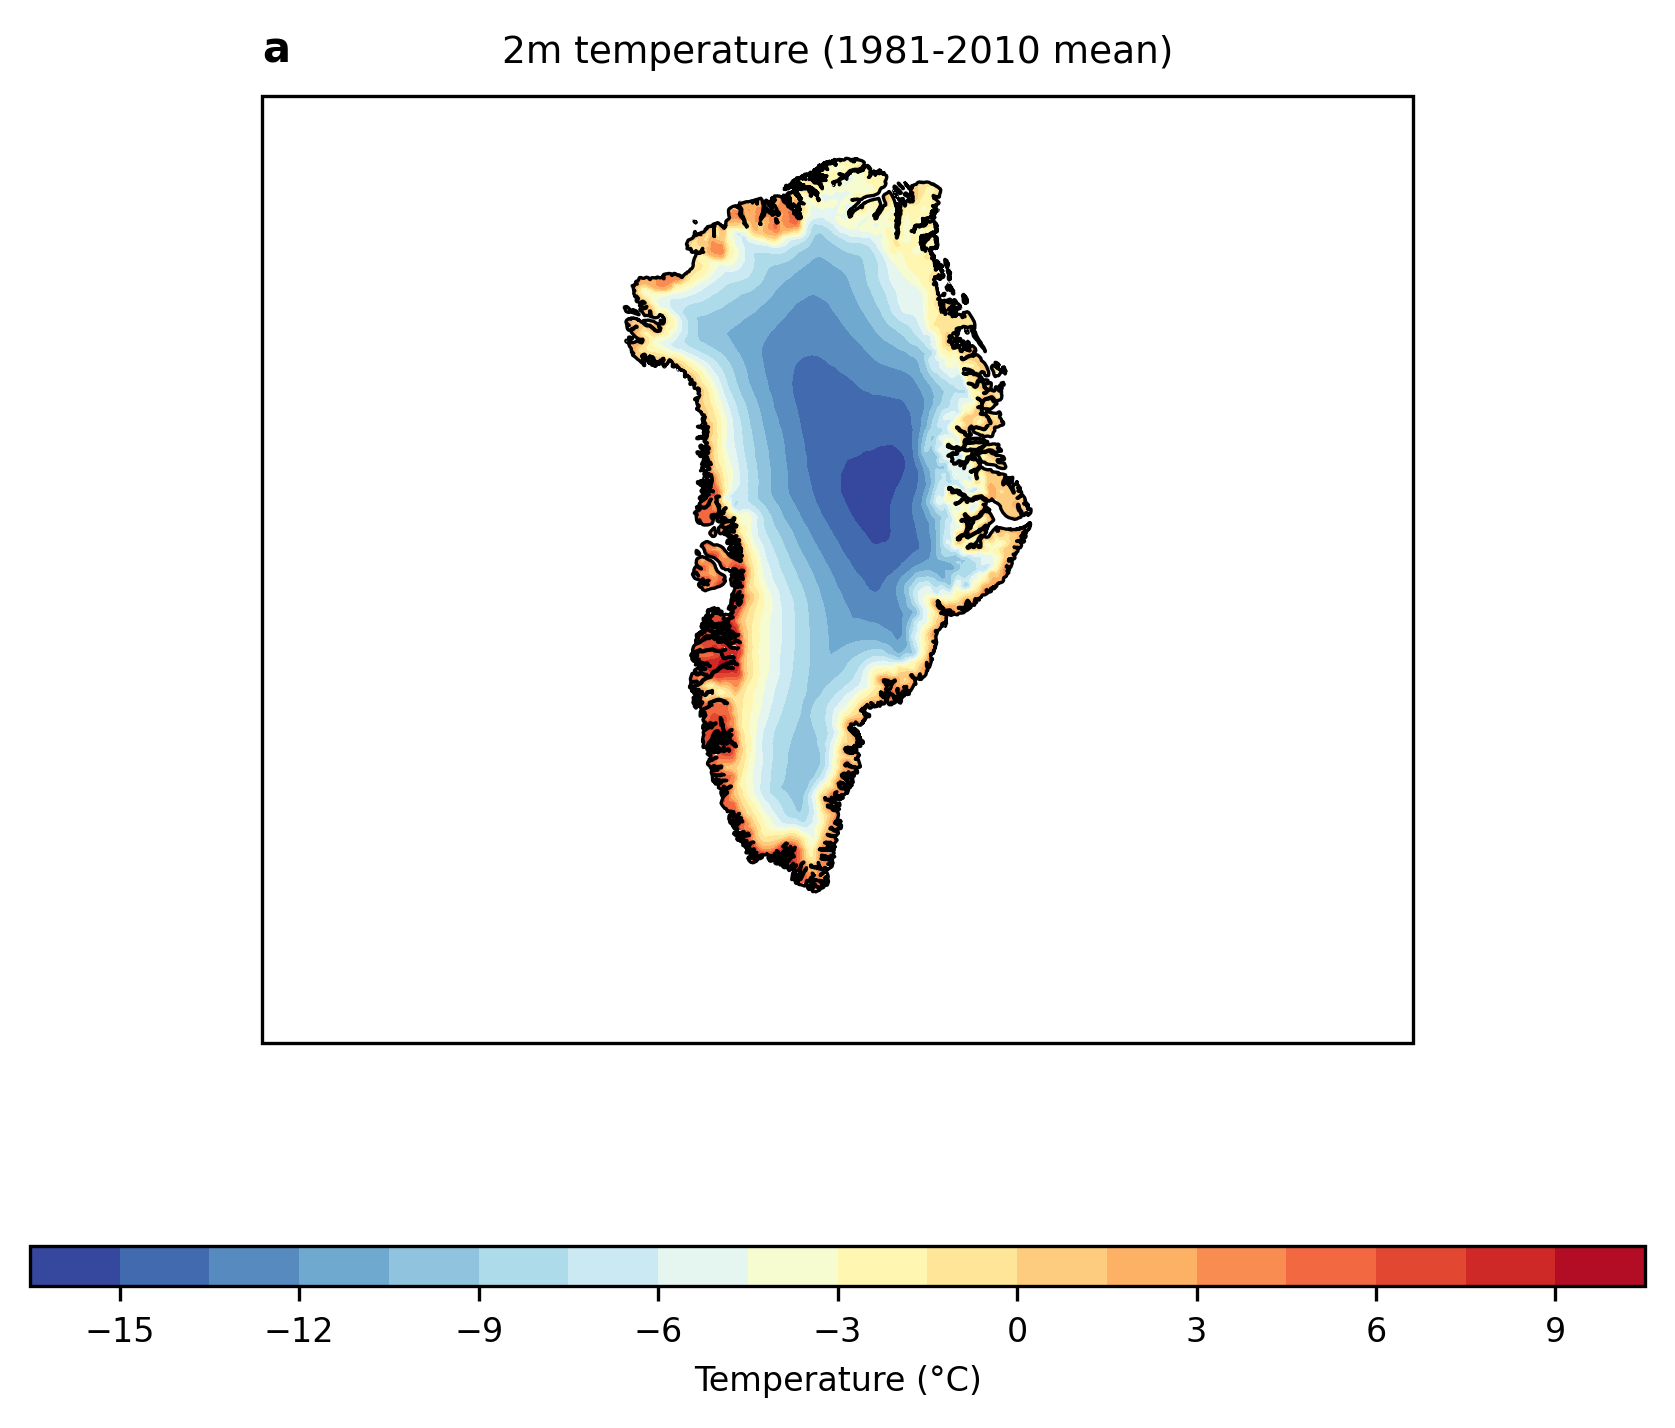

C:\Users\11823\AppData\Local\Temp\ipykernel_9240\1696395964.py:121: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


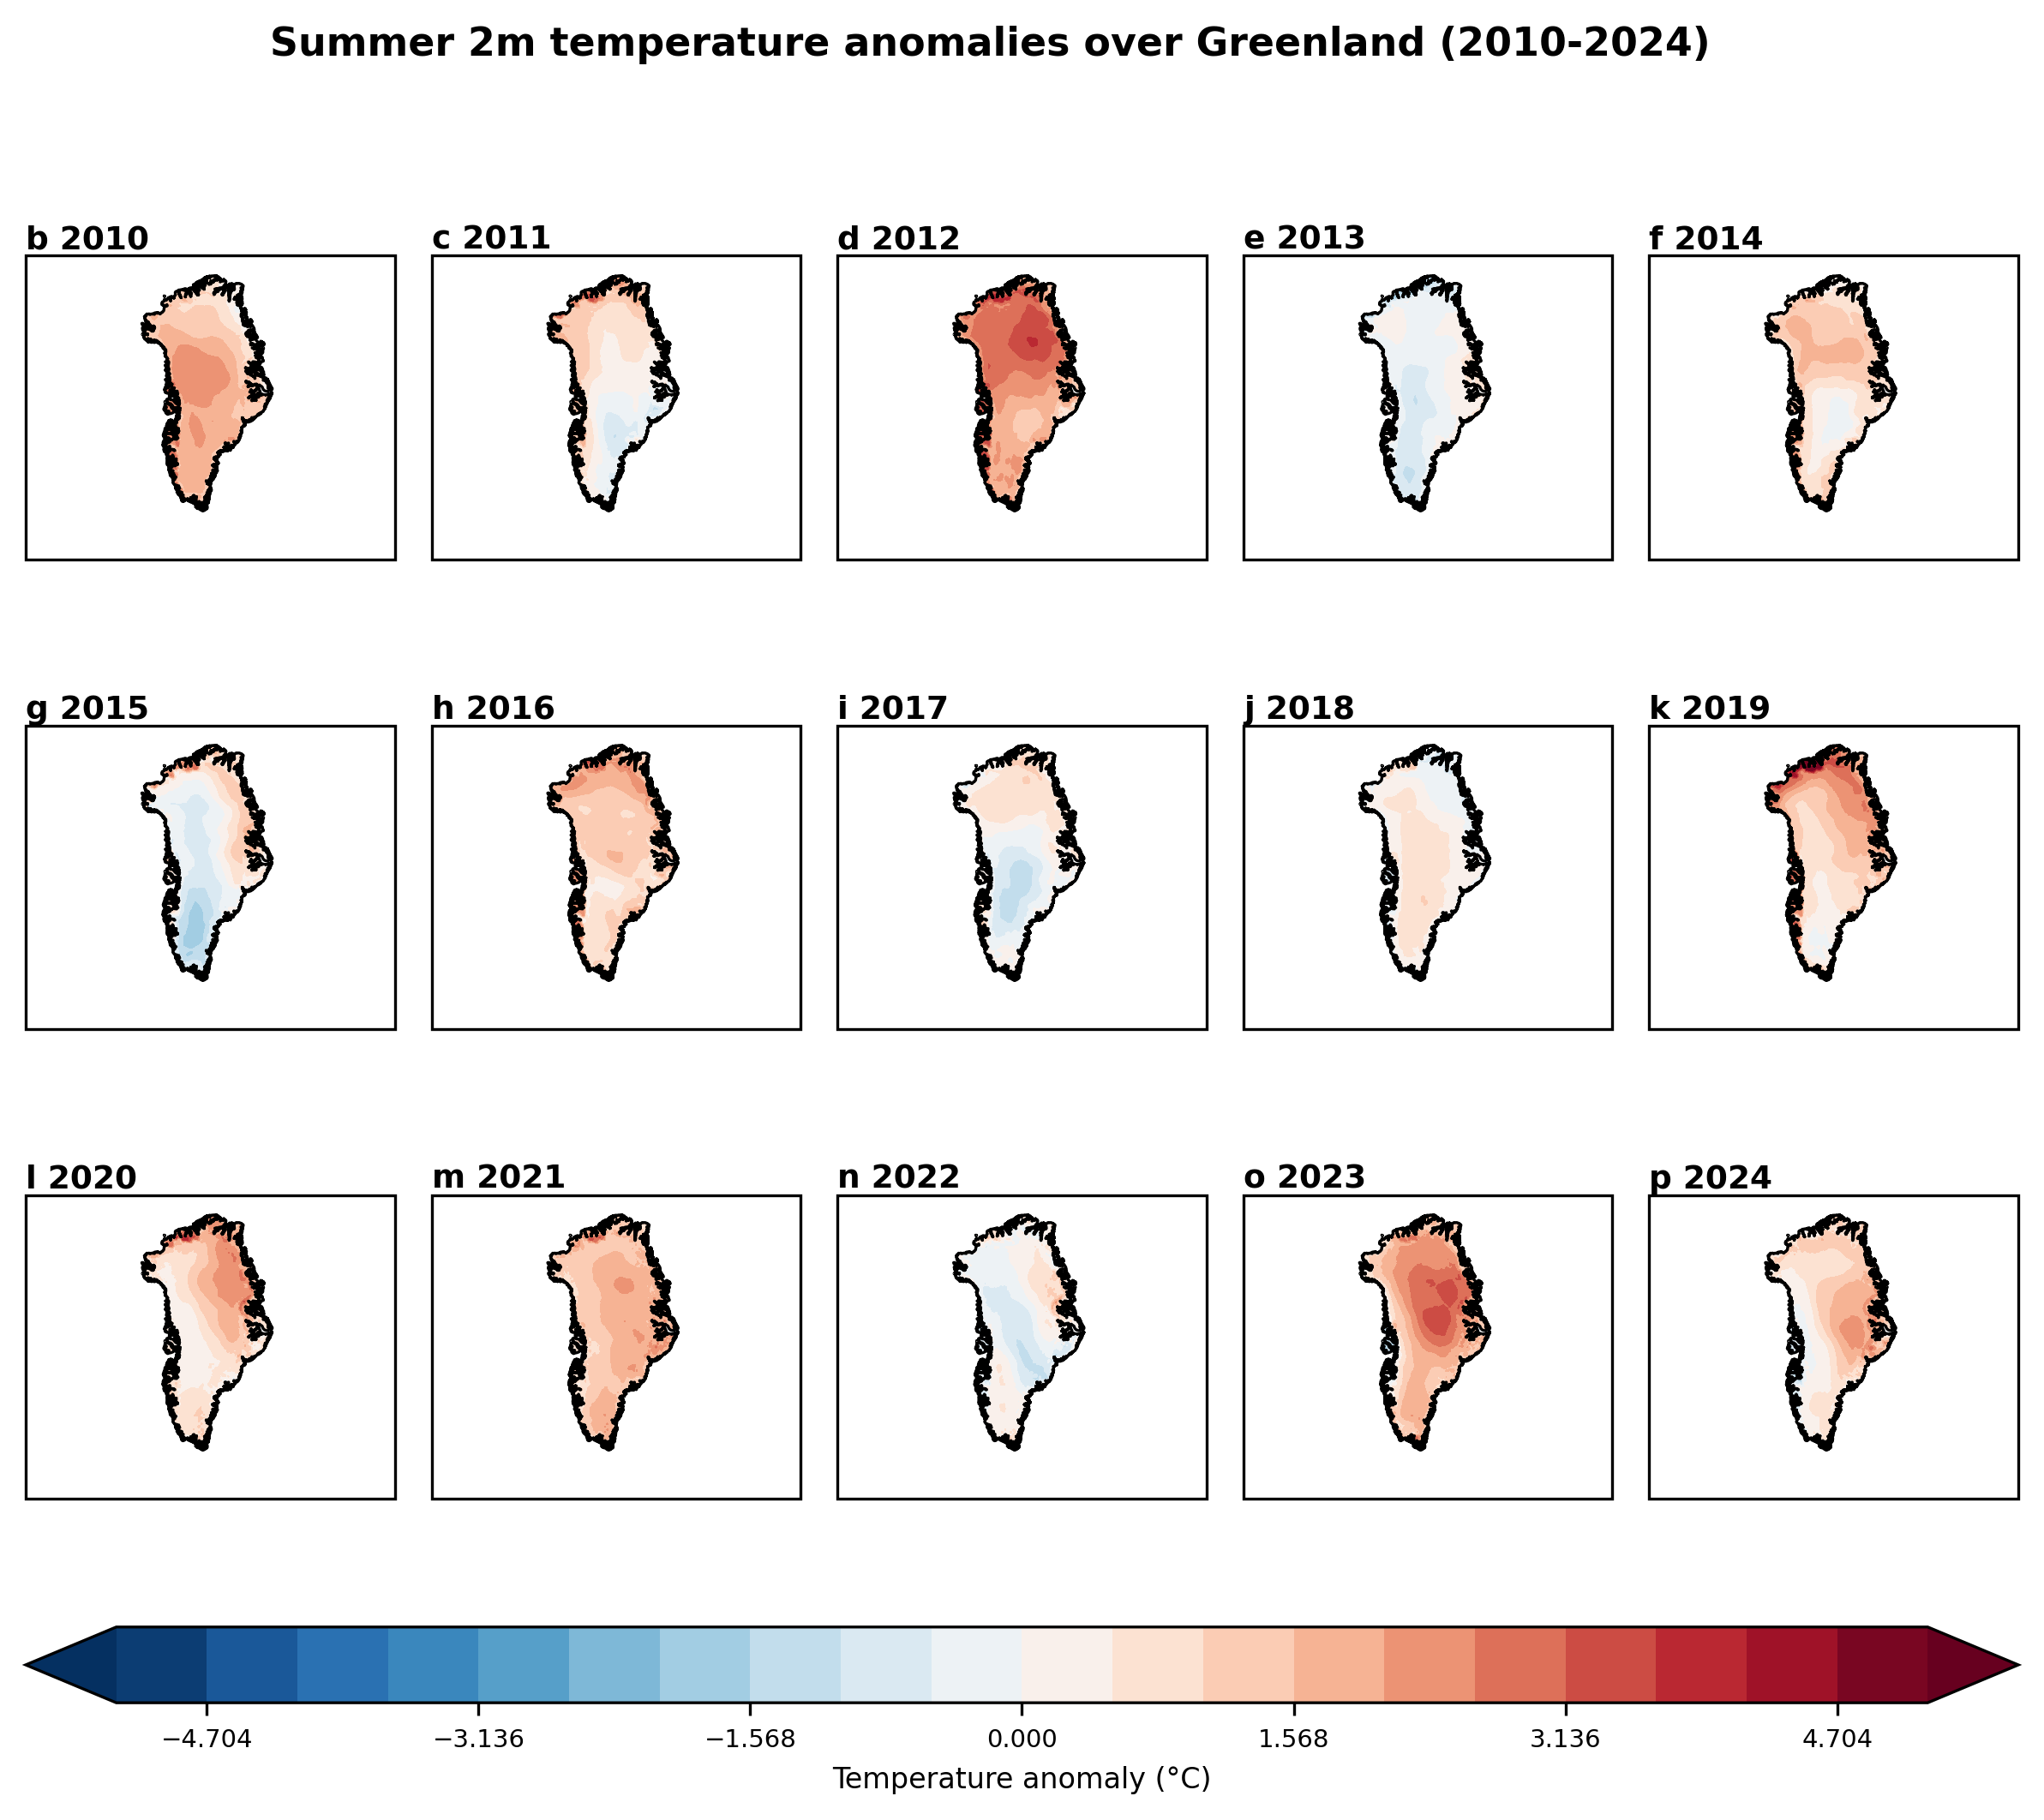

In [8]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
from matplotlib.gridspec import GridSpec

# === 1. 加载数据 ===
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
ds = xr.open_dataset(file_path)
t2m = ds['t2m']

# 单位转换：K → °C
if t2m.max() > 100:
    t2m = t2m - 273.15

# === 2. 加载格陵兰轮廓 ===
greenland_shp = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
greenland_geom = Reader(greenland_shp).geometries()
greenland_feature = cfeature.ShapelyFeature(greenland_geom, ccrs.PlateCarree(), 
                                          facecolor='none', edgecolor='black', linewidth=0.8)

# === 3. 定义分析函数 ===
def analyze_t2m(data, years_range, plot_years):
    """温度分析函数"""
    # 计算气候平均
    clim = data.sel(valid_time=slice(f"{years_range[0]}-06-01", f"{years_range[1]}-08-31"))
    clim_monthly = clim.groupby('valid_time.month').mean(dim='valid_time')
    clim_jja = clim_monthly.sel(month=[6, 7, 8]).mean(dim='month')
    
    # 计算距平
    anomalies = {}
    for year in plot_years:
        summer = data.sel(valid_time=slice(f"{year}-06-01", f"{year}-08-31"))
        summer_mean = summer.mean(dim='valid_time')
        anomalies[year] = summer_mean - clim_jja
    
    return clim_jja, anomalies

# === 4. 执行分析 ===
clim_jja, anomalies = analyze_t2m(t2m, (1981, 2010), range(2010, 2025))

# === 5. 绘图设置 ===
plt.style.use('default')
plt.rcParams.update({
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.titlesize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.format': 'tiff',
    'savefig.bbox': 'tight'
})
proj = ccrs.NorthPolarStereo(central_longitude=-45)  # 调整中心经度

# === 6. 绘制气候基准图 ===
fig1 = plt.figure(figsize=(7, 5))
ax = plt.subplot(projection=proj)
ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
ax.add_feature(greenland_feature)  # 仅添加格陵兰轮廓
ax.set_title("a", loc='left', weight='bold', fontsize=10, pad=-15)
ax.set_title("2m temperature (1981-2010 mean)", fontsize=9, pad=8)

cf = ax.contourf(
    clim_jja.longitude,
    clim_jja.latitude,
    clim_jja,
    levels=20,
    cmap='RdYlBu_r',
    transform=ccrs.PlateCarree()
)

cbar = fig1.colorbar(cf, orientation='horizontal', pad=0.15, shrink=0.8, aspect=40)
cbar.set_label("Temperature (°C)", fontsize=8)
plt.tight_layout()
plt.savefig("Fig1_T2M_Climatology.tiff")
plt.show()

# === 7. 绘制距平图 (2010-2024) ===
years = sorted(anomalies.keys())
nrows = (len(years) + 4) // 5  # 每行5年

fig2 = plt.figure(figsize=(10, 2.5 * nrows))
gs = GridSpec(nrows + 1, 5, height_ratios=[1]*nrows + [0.2], hspace=0.3, wspace=0.1)

# 温度距平范围设置
anom_max = max(abs(anom.max().values) for anom in anomalies.values())
anom_levels = np.linspace(-anom_max, anom_max, 21)

for i, year in enumerate(years):
    row = i // 5
    col = i % 5
    
    ax = plt.subplot(gs[row, col], projection=proj)
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(greenland_feature)  # 仅添加格陵兰轮廓
    ax.set_title(f"{chr(98+i)} {year}", loc='left', weight='bold', fontsize=9, pad=-15)
    
    cf = ax.contourf(
        anomalies[year].longitude,
        anomalies[year].latitude,
        anomalies[year],
        levels=anom_levels,
        cmap='RdBu_r',
        extend='both',
        transform=ccrs.PlateCarree()
    )

# 添加共享colorbar
cax = plt.subplot(gs[-1, :])
cbar = fig2.colorbar(cf, cax=cax, orientation='horizontal')
cbar.set_label("Temperature anomaly (°C)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.suptitle("Summer 2m temperature anomalies over Greenland (2010-2024)", 
             y=0.98, fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig("Fig2_T2M_Annual_Anomalies.tiff")
plt.show()

数据集变量: ['spatial_ref', 'sf', 'tp', 'rf']


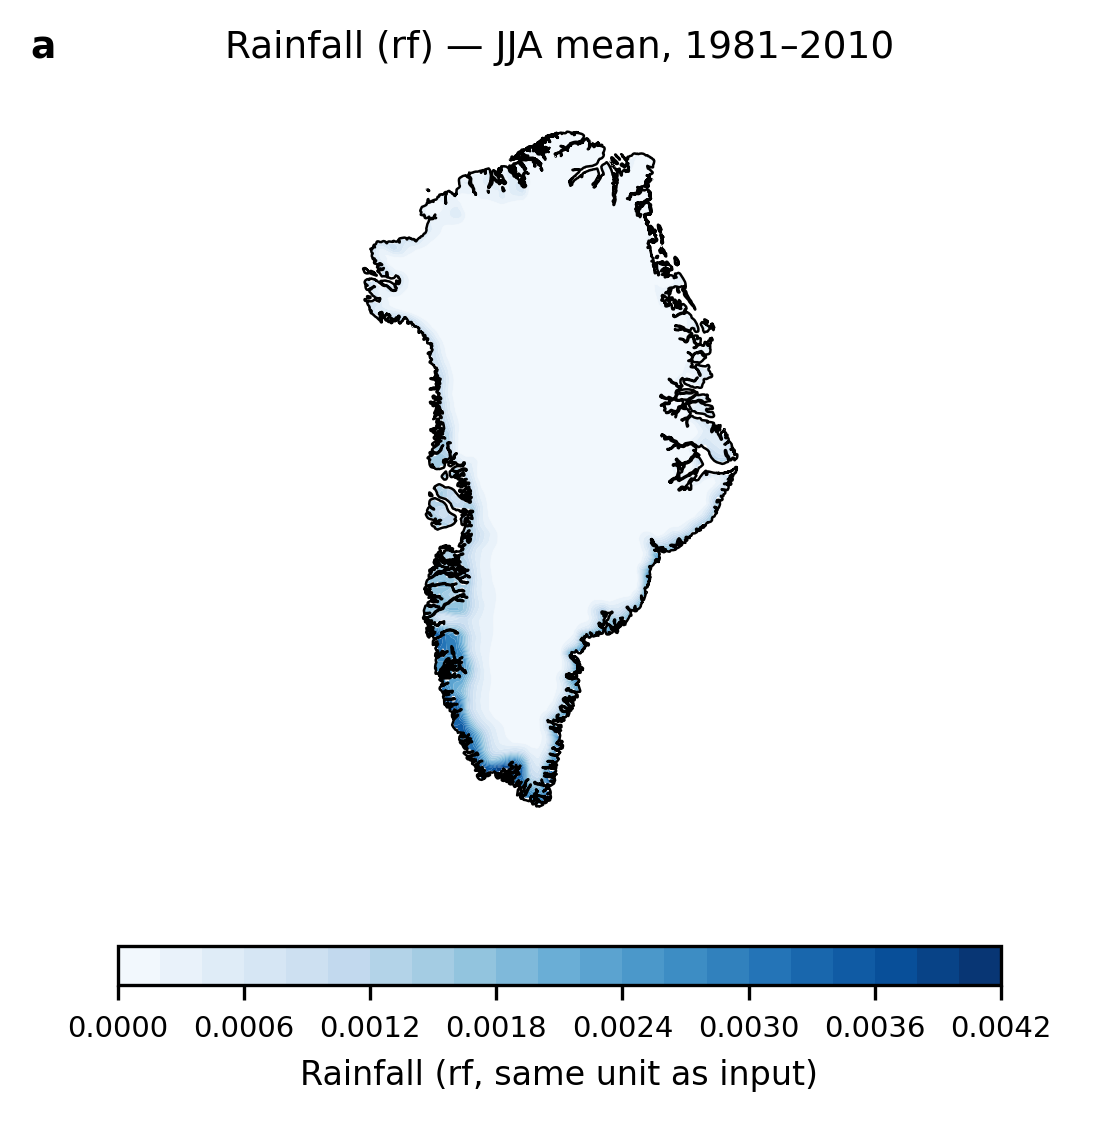

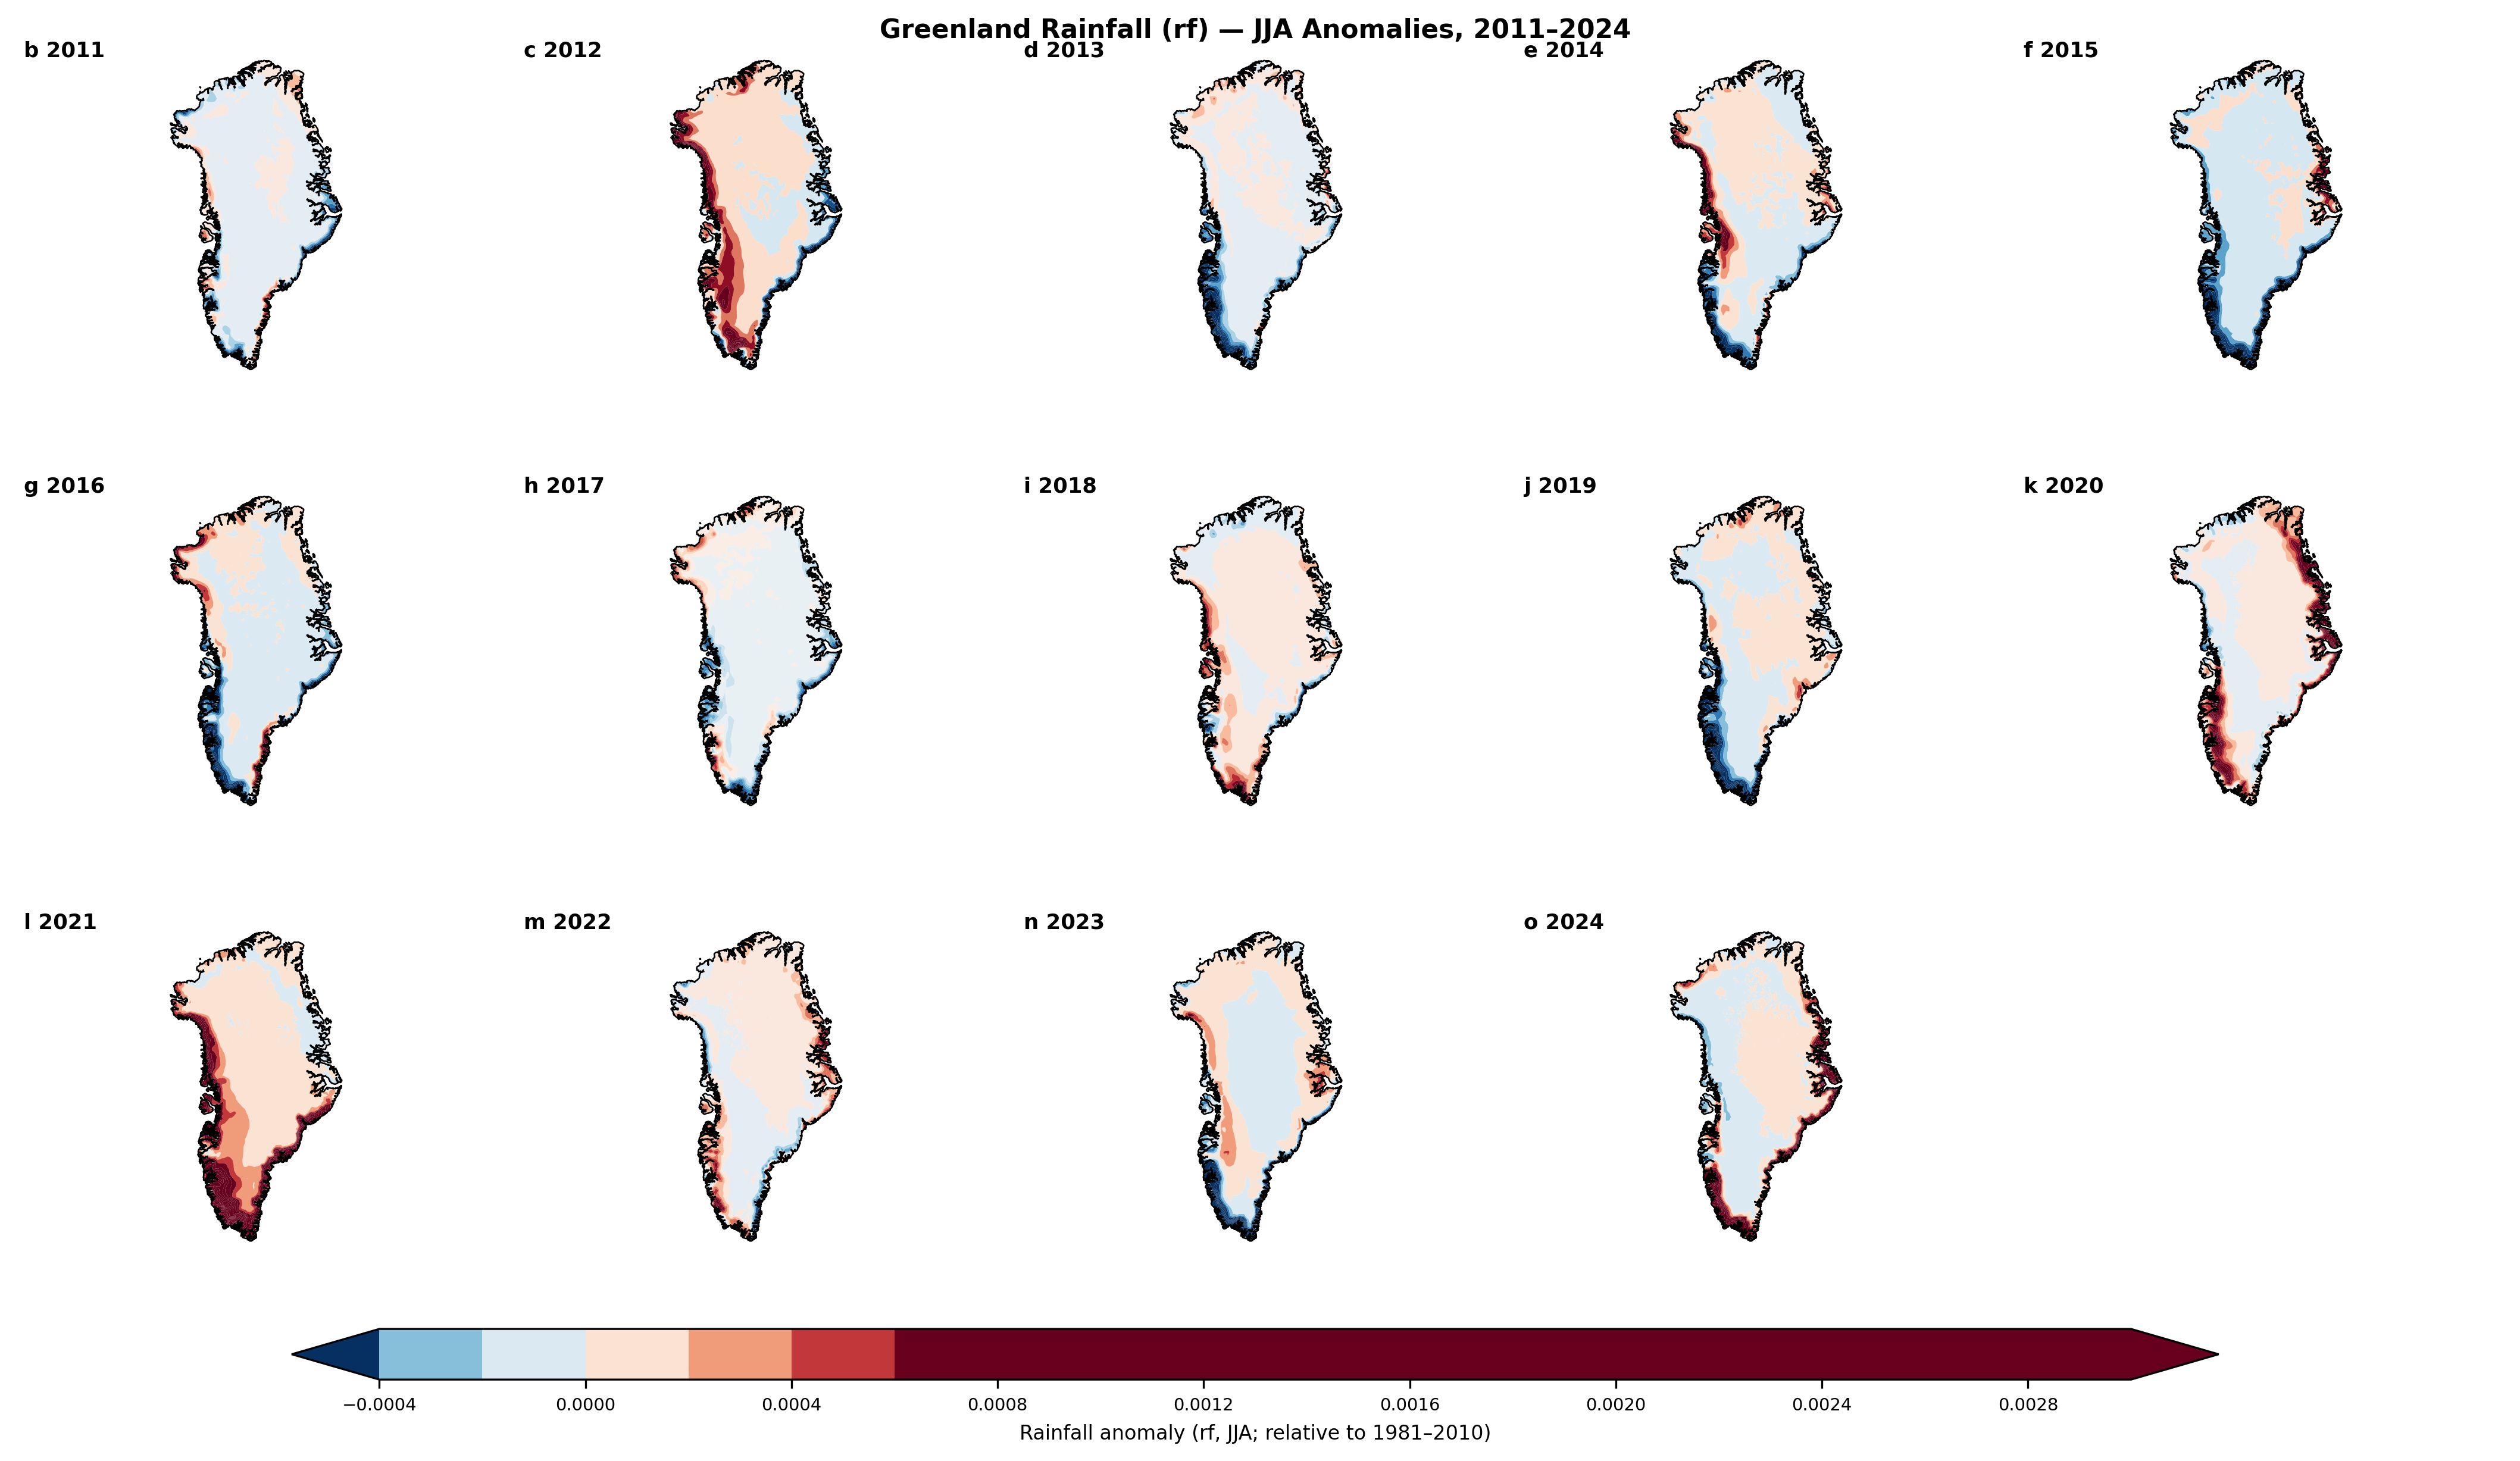

In [3]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
from matplotlib.colors import TwoSlopeNorm

# ========== 1) 数据 ==========
nc_path = r"E:\TUB\greenland\sf_tp_rf.nc"
ds = xr.open_dataset(nc_path)
print("数据集变量:", list(ds.data_vars))
var_name = 'rf' if 'rf' in ds.data_vars else list(ds.data_vars)[0]
da = ds[var_name]

# 时间维 / 经纬度名自适应
time_dim = 'valid_time' if 'valid_time' in da.dims else ('time' if 'time' in da.dims else None)
if time_dim is None:
    raise ValueError("未找到时间维（valid_time 或 time）")

def pick_coord_names(da):
    lon = next((n for n in ['longitude','lon','x'] if n in da.coords), None)
    lat = next((n for n in ['latitude','lat','y']   if n in da.coords), None)
    if lon is None or lat is None:
        raise ValueError("未找到经纬度坐标（longitude/latitude 或 lon/lat）")
    return lon, lat
lon_name, lat_name = pick_coord_names(da)

# 投影、范围与边界
proj   = ccrs.NorthPolarStereo(central_longitude=-45)
extent = [-75, -10, 55, 85]
greenland_shp = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
greenland_geom = list(Reader(greenland_shp).geometries())
greenland_feature = cfeature.ShapelyFeature(
    greenland_geom, ccrs.PlateCarree(), facecolor='none', edgecolor='black', linewidth=0.6
)

# ========== 2) 计算基准与距平 ==========
def compute_base_and_anoms(dataarray, years_base=(1981,2010), years_plot=range(2011,2025)):
    clim = dataarray.sel(**{time_dim: slice(f"{years_base[0]}-06-01", f"{years_base[1]}-08-31")})
    clim_monthly = clim.groupby(f"{time_dim}.month").mean(dim=time_dim)
    base_jja = clim_monthly.sel(month=[6,7,8]).mean(dim='month')
    anoms = {}
    for y in years_plot:
        summer = dataarray.sel(**{time_dim: slice(f"{y}-06-01", f"{y}-08-31")})
        summer_mean = summer.mean(dim=time_dim)
        anoms[y] = summer_mean - base_jja
    return base_jja, anoms

years = list(range(2011, 2025))  # 14 年
base_jja, anoms = compute_base_and_anoms(da, years_plot=years)

# ========== 3) 通用样式 ==========
plt.rcParams.update({
    'font.size': 8.5, 'axes.titlesize': 9, 'figure.dpi': 300,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.format': 'tiff'
})

def tidy_axes(ax):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(greenland_feature, zorder=3)
    # 清理边框/刻度，避免空白
    for attr in ['spines']:
        obj = getattr(ax, attr, None)
        if obj:
            for s in obj.values():
                try: s.set_visible(False)
                except: pass
    ax.set_xticks([]); ax.set_yticks([])
    try: ax.set_frame_on(False)
    except: pass

# ========== 4) 基准图（更小更紧凑） ==========
fig1 = plt.figure(figsize=(4.6, 3.3))
ax = fig1.add_axes([0.02, 0.08, 0.96, 0.88], projection=proj)  # 手动轴域，极小边距
tidy_axes(ax)
ax.set_title("a", loc='left', weight='bold', fontsize=9, pad=-10)
ax.set_title("Rainfall (rf) — JJA mean, 1981–2010", fontsize=9, pad=4)

cf = ax.contourf(
    base_jja[lon_name], base_jja[lat_name], base_jja,
    levels=21, cmap='Blues', transform=ccrs.PlateCarree(), antialiased=True
)

cax = fig1.add_axes([0.18, 0.04, 0.64, 0.04])  # 极薄横向色标
cbar = fig1.colorbar(cf, cax=cax, orientation='horizontal')
cbar.set_label("Rainfall (rf, same unit as input)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

fig1.savefig("Fig1_RF_JJA_Climatology_1981-2010.tiff")
plt.show()

# ========== 5) 年度距平：3 行 × 5 列（紧凑） ==========
nrows, ncols = 3, 5
total = nrows * ncols  # 15
fig_w, fig_h = 14.2, 8.1  # 画布尺寸，保证单幅图尽可能大
fig2 = plt.figure(figsize=(fig_w, fig_h))

# 手动布局，严控空白（四边留白+行列间距都极小）
left, right, bottom, top = 0.012, 0.992, 0.10, 0.992
hspace, wspace = 0.012, 0.006
panel_w = (right - left - (ncols - 1) * wspace) / ncols
panel_h = (top - bottom - (nrows - 1) * hspace) / nrows

# 稳健、对称、零中心色标
vals = np.concatenate([np.ravel(anoms[y].values) for y in years])
vals = vals[np.isfinite(vals)]
if vals.size:
    p2, p98 = np.percentile(vals, [2, 98])
    M = max(abs(p2), abs(p98))
    vmin, vmax = -M, M
else:
    vmin, vmax = -0.1, 0.1
norm = TwoSlopeNorm(vcenter=0.0, vmin=vmin, vmax=vmax)

last = None
# 前 14 个格子放 2011–2024，第 15 个格子留空
for i, y in enumerate(years):
    r, c = divmod(i, ncols)
    x0 = left + c * (panel_w + wspace)
    y0 = top - (r + 1) * panel_h - r * hspace
    ax = fig2.add_axes([x0, y0, panel_w, panel_h], projection=proj)
    tidy_axes(ax)
    ax.text(0.012, 0.985, f"{chr(98+i)} {y}", transform=ax.transAxes,
            va='top', ha='left', fontsize=8.5, weight='bold', zorder=5)
    an = anoms[y]
    last = ax.contourf(
        an[lon_name], an[lat_name], an,
        levels=21, cmap='RdBu_r', norm=norm, extend='both',
        transform=ccrs.PlateCarree(), antialiased=True
    )

# 共享色标（窄且靠下，进一步压缩空白）
cax = fig2.add_axes([0.12, 0.055, 0.76, 0.035])
cbar = fig2.colorbar(last, cax=cax, orientation='horizontal')
cbar.set_label("Rainfall anomaly (rf, JJA; relative to 1981–2010)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# 紧凑主标题
fig2.text(0.5, 0.997, "Greenland Rainfall (rf) — JJA Anomalies, 2011–2024",
          ha='center', va='top', fontsize=10.5, weight='bold')

fig2.savefig("Fig2_RF_JJA_Anomalies_2011-2024_3x5.tiff")
plt.show()


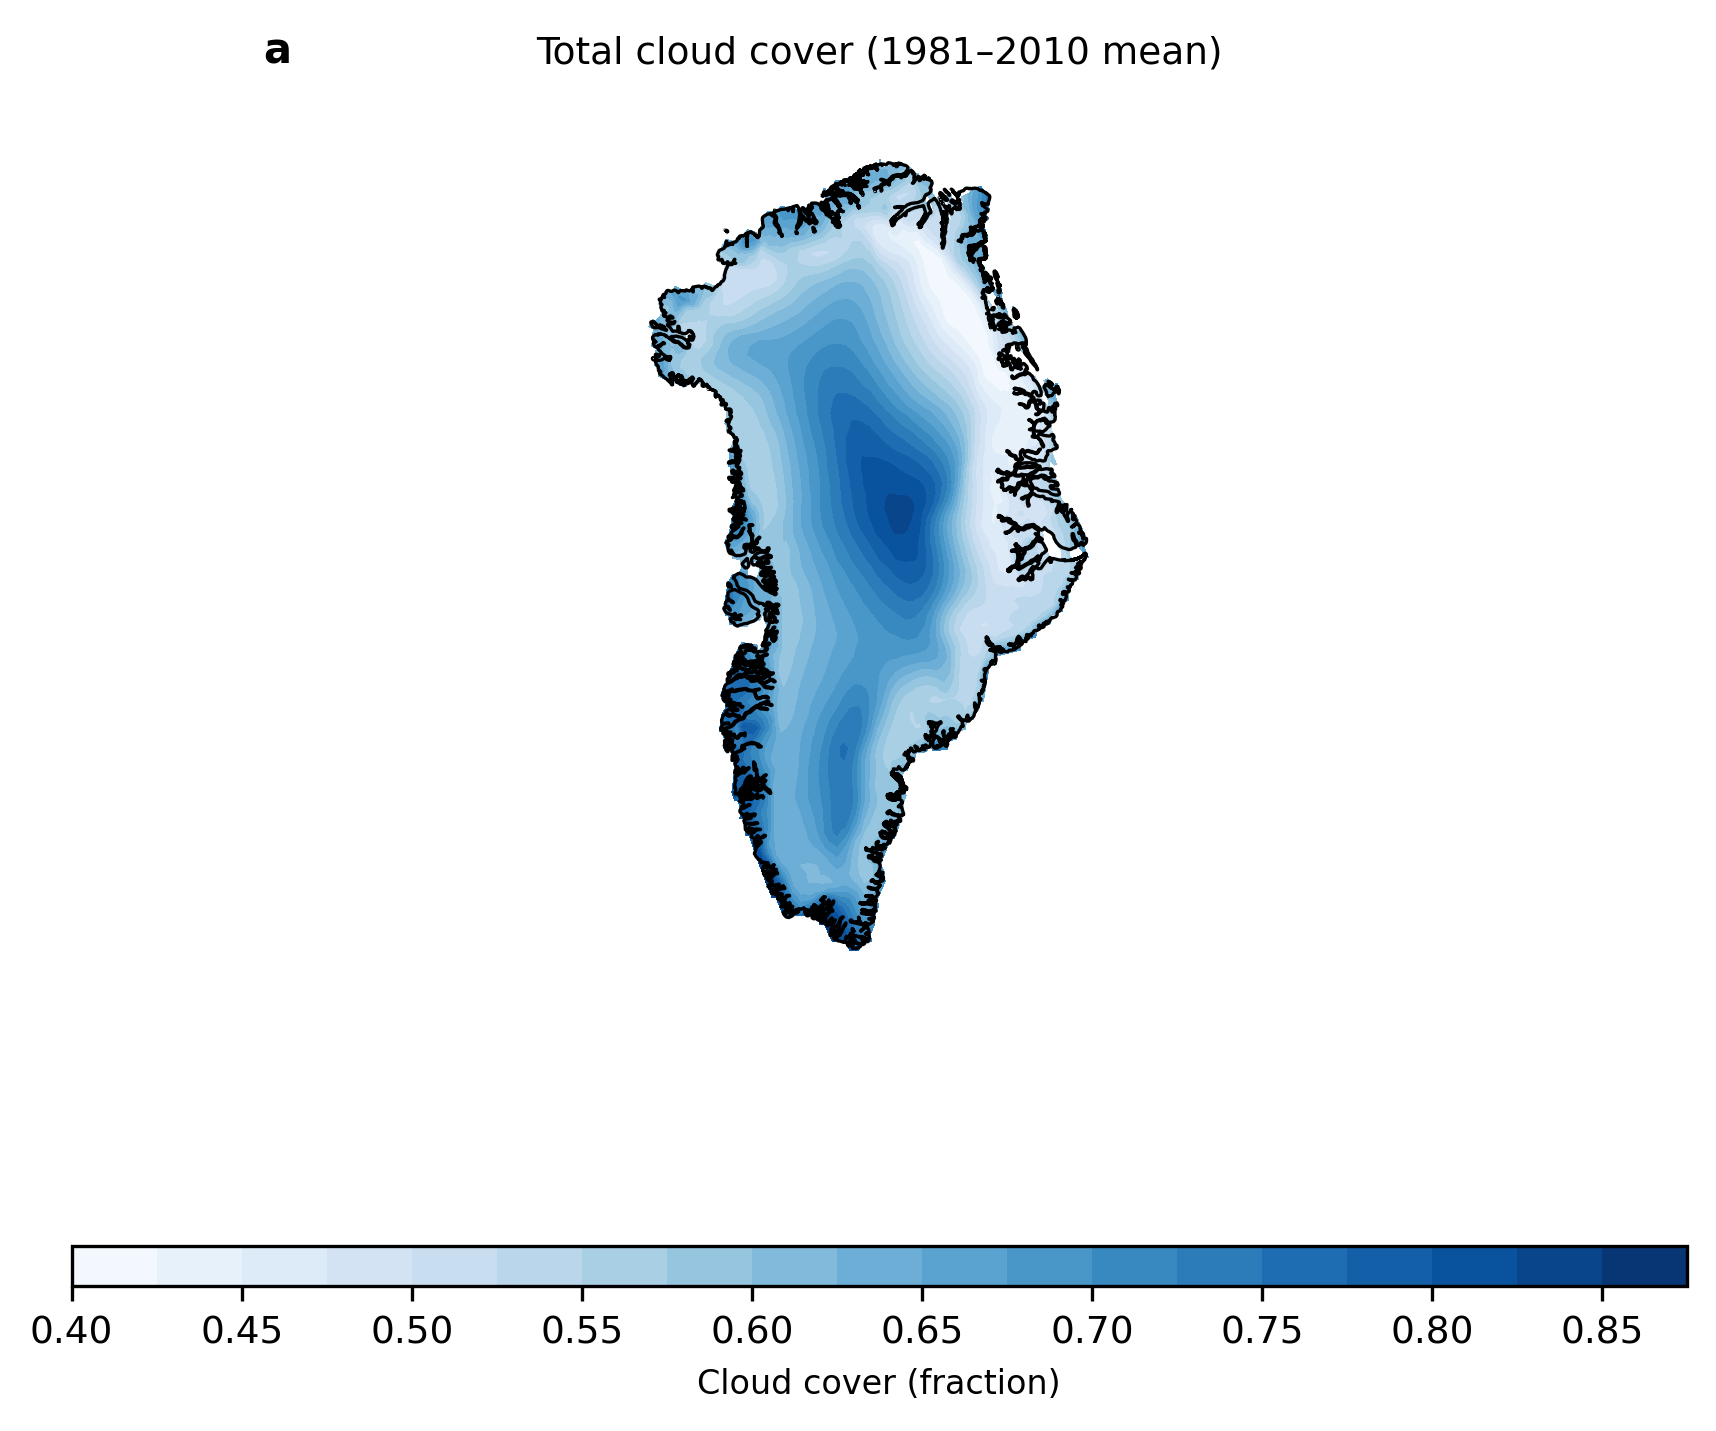

C:\Users\11823\AppData\Local\Temp\ipykernel_4608\3705513102.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


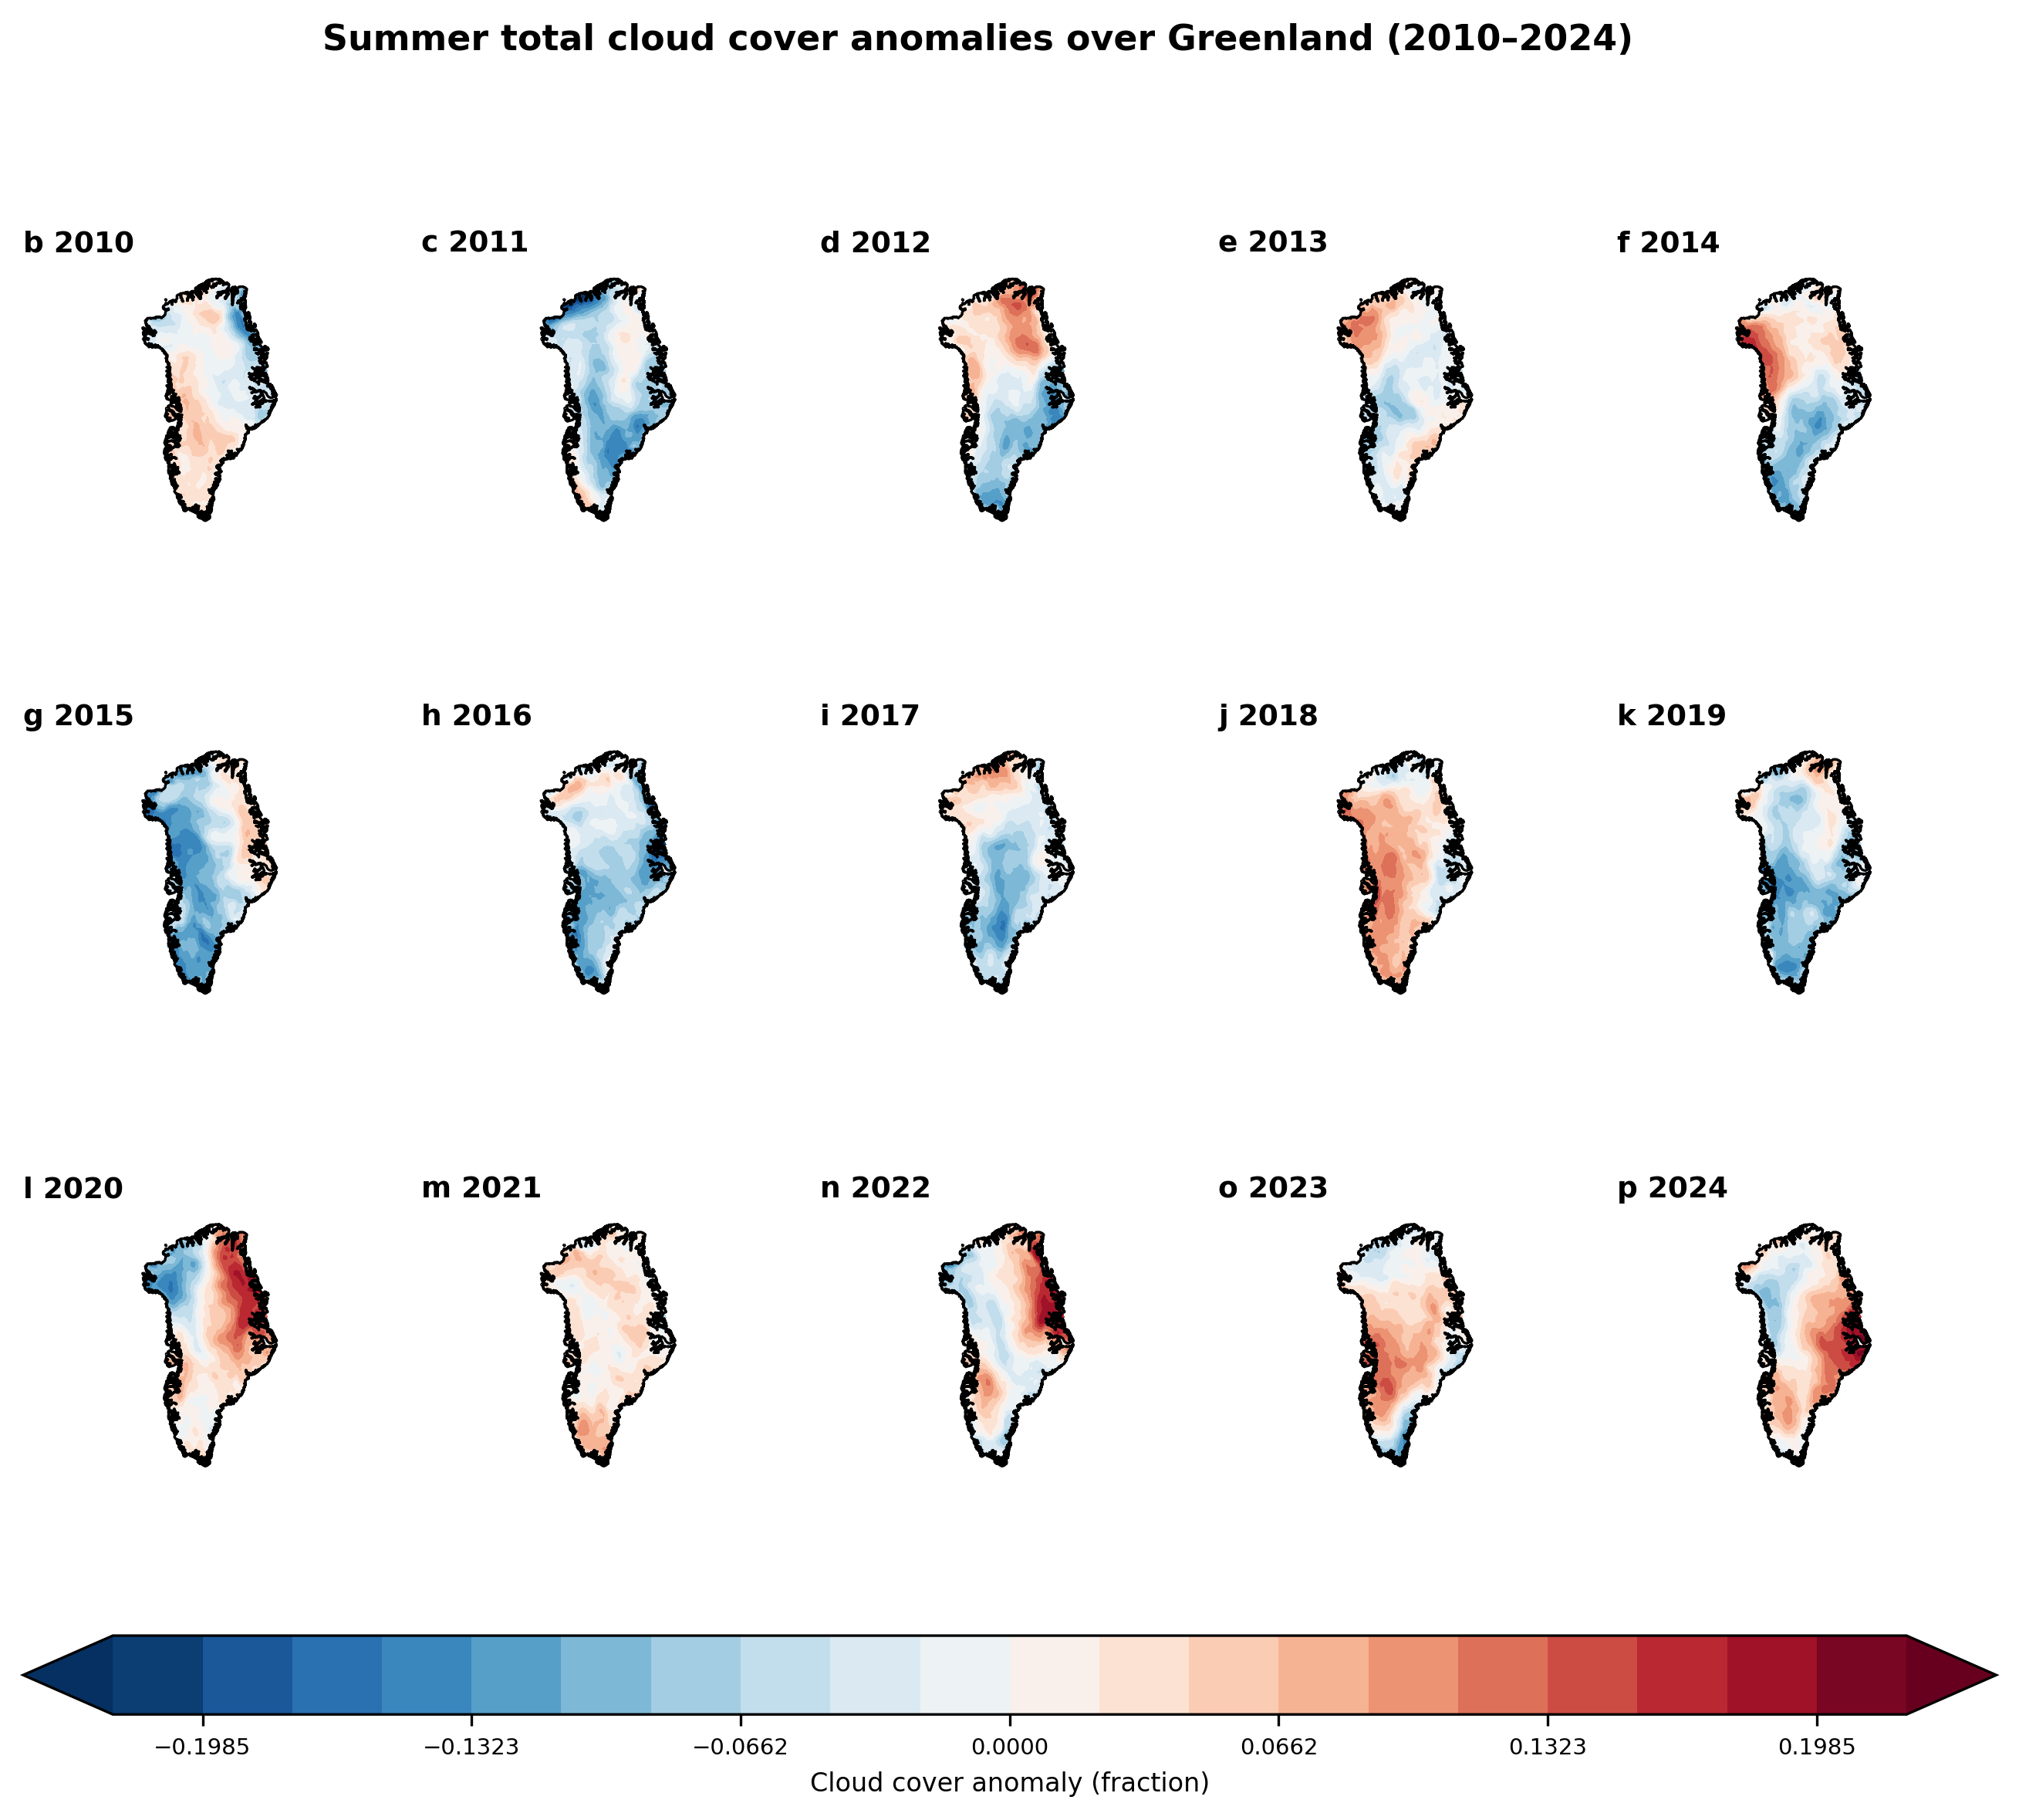

In [1]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
from matplotlib.gridspec import GridSpec

# === 1. 加载数据 ===
file_path = r"F:\TUB\greenlandProject\ERA5LAND\greenland_tcc_full.nc"
ds = xr.open_dataset(file_path)
tcc = ds['tcc']  # total cloud cover, 单位: 0~1

# === 2. 加载格陵兰轮廓 ===
greenland_shp = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
greenland_geom = Reader(greenland_shp).geometries()
greenland_feature = cfeature.ShapelyFeature(
    greenland_geom, ccrs.PlateCarree(), facecolor='none', edgecolor='black', linewidth=0.8
)

# === 3. 分析函数 ===
def analyze_tcc(data, years_range, plot_years):
    """云量分析函数"""
    clim = data.sel(valid_time=slice(f"{years_range[0]}-06-01", f"{years_range[1]}-08-31"))
    clim_monthly = clim.groupby('valid_time.month').mean(dim='valid_time')
    clim_jja = clim_monthly.sel(month=[6, 7, 8]).mean(dim='month')

    anomalies = {}
    for year in plot_years:
        summer = data.sel(valid_time=slice(f"{year}-06-01", f"{year}-08-31"))
        summer_mean = summer.mean(dim='valid_time')
        anomalies[year] = summer_mean - clim_jja
    return clim_jja, anomalies

# === 4. 执行分析 ===
clim_jja, anomalies = analyze_tcc(tcc, (1981, 2010), range(2010, 2025))

# === 5. 绘图参数 ===
plt.rcParams.update({
    'font.size': 9,
    'axes.titlesize': 10,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.format': 'tiff',
    'savefig.bbox': 'tight'
})
proj = ccrs.NorthPolarStereo(central_longitude=-45)

# === 6. 基准期平均图 ===
fig1 = plt.figure(figsize=(7, 5))
ax = plt.subplot(projection=proj)
ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
ax.add_feature(greenland_feature)
ax.set_axis_off()  # 去掉边框与刻度
ax.set_title("a", loc='left', weight='bold', fontsize=10, pad=-15)
ax.set_title("Total cloud cover (1981–2010 mean)", fontsize=9, pad=8)

cf = ax.contourf(
    clim_jja.longitude, clim_jja.latitude, clim_jja,
    levels=20, cmap='Blues', transform=ccrs.PlateCarree()
)
cbar = fig1.colorbar(cf, orientation='horizontal', pad=0.1, shrink=0.8, aspect=40)
cbar.set_label("Cloud cover (fraction)", fontsize=8)
plt.tight_layout()
plt.savefig("Fig1_TCC_Climatology.tiff")
plt.show()

# === 7. 年际距平图 ===
years = sorted(anomalies.keys())
nrows = (len(years) + 4) // 5

fig2 = plt.figure(figsize=(11, 2.8 * nrows))  # 每个子图更大
gs = GridSpec(nrows + 1, 5, height_ratios=[1]*nrows + [0.2], hspace=0.25, wspace=0.05)

anom_max = max(abs(anom.max().values) for anom in anomalies.values())
anom_levels = np.linspace(-anom_max, anom_max, 21)

for i, year in enumerate(years):
    row, col = divmod(i, 5)
    ax = plt.subplot(gs[row, col], projection=proj)
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(greenland_feature)
    ax.set_axis_off()
    ax.set_title(f"{chr(98+i)} {year}", loc='left', weight='bold', fontsize=9, pad=-15)

    cf = ax.contourf(
        anomalies[year].longitude, anomalies[year].latitude, anomalies[year],
        levels=anom_levels, cmap='RdBu_r', extend='both',
        transform=ccrs.PlateCarree()
    )

# 添加共享色标
cax = plt.subplot(gs[-1, :])
cbar = fig2.colorbar(cf, cax=cax, orientation='horizontal')
cbar.set_label("Cloud cover anomaly (fraction)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.suptitle("Summer total cloud cover anomalies over Greenland (2010–2024)",
             y=0.98, fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig("Fig2_TCC_Annual_Anomalies.tiff")
plt.show()


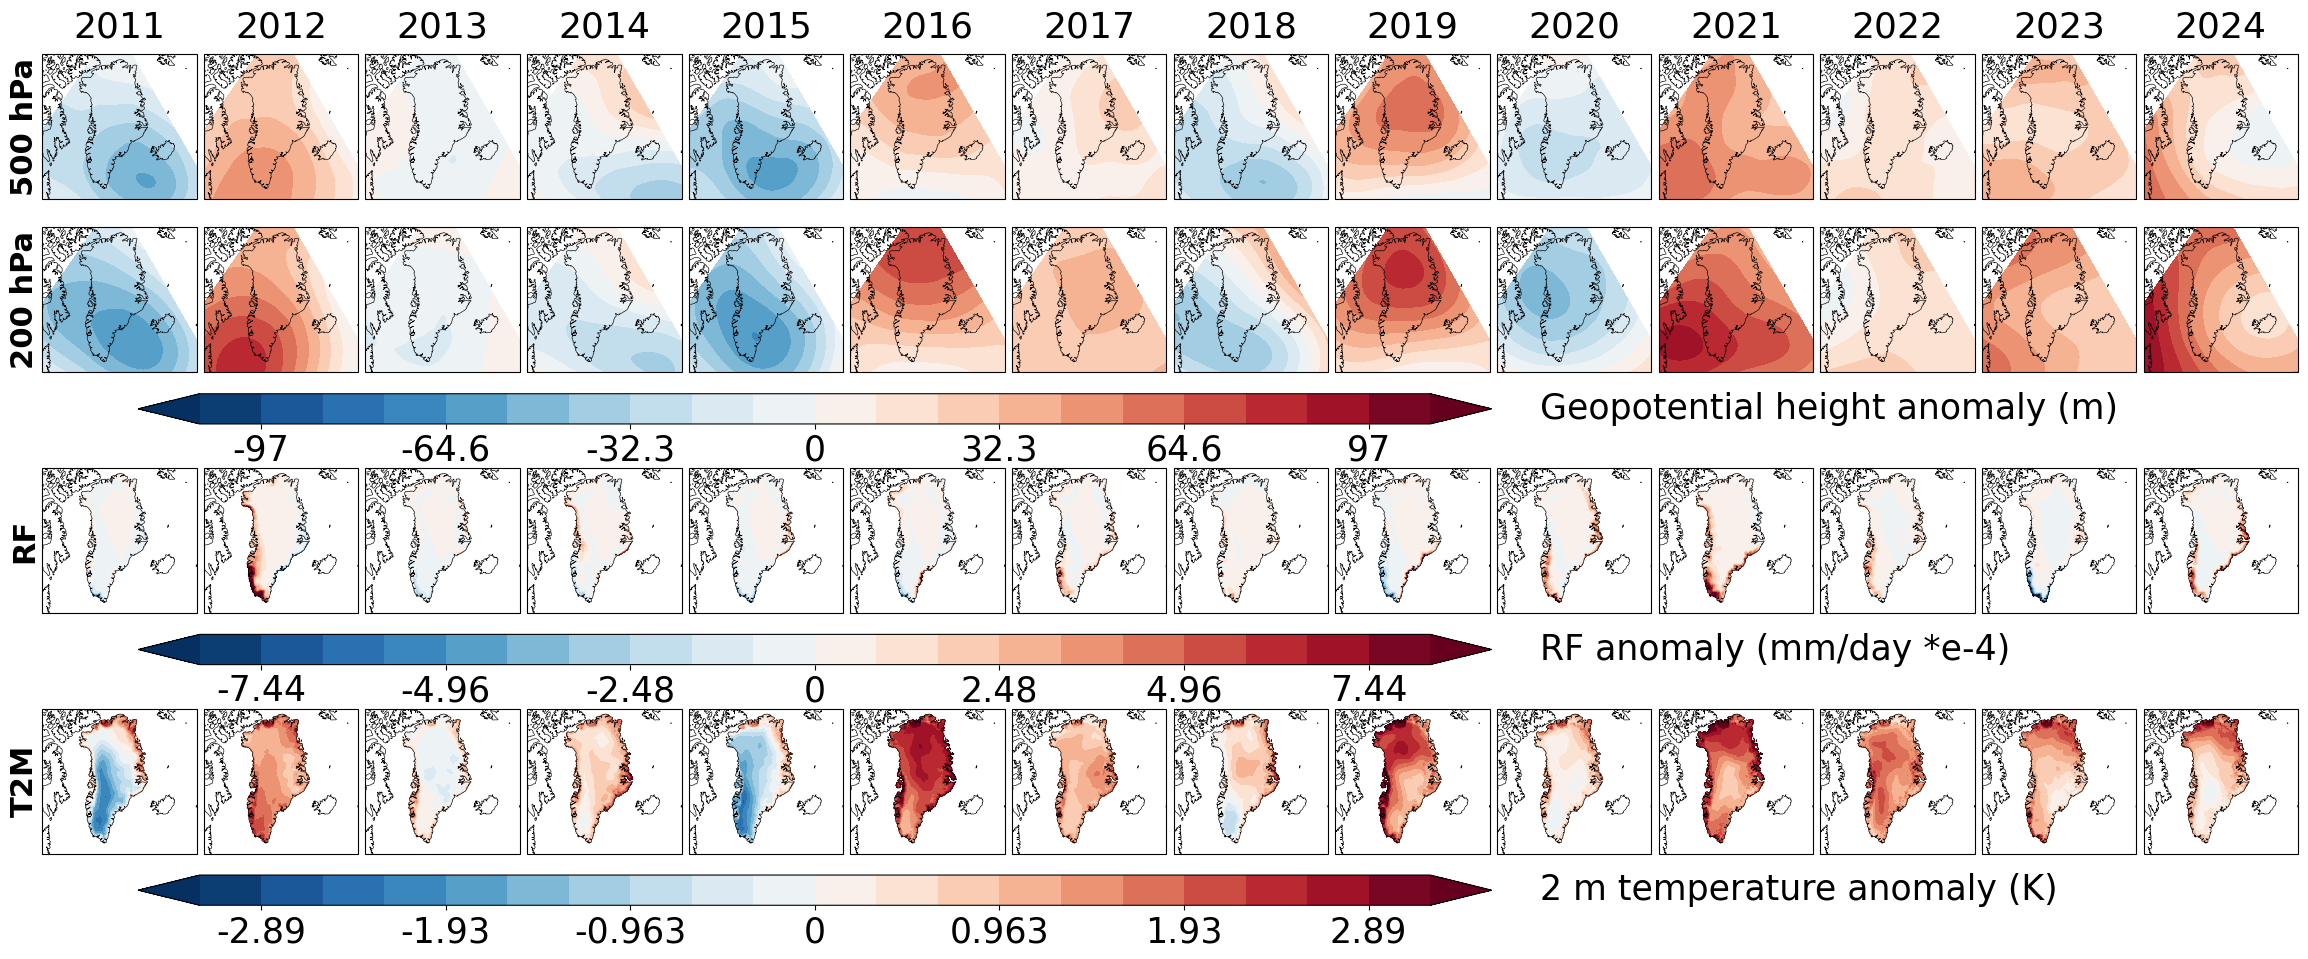

In [28]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ======================= 全局参数（你改这里） =======================
FONT_SIZE       = 30    # 保留用于其他可能的文字
ROW_LABEL_SIZE  = 22    # 行标：500 hPa / 200 hPa / RF / T2M
YEAR_FONT_SIZE  = 26    # 年份标签字号（只在首排）
# 图例相关字号
CBAR_LABEL_SIZE = 25    # 色条标签字号
CBAR_TICK_SIZE  = 25    # 色条刻度字号
# 布局：行高、行距、色条高度 & 上/下间距（保证不压图）
ROW_H           = 0.125     # 单排子图高度（figure 坐标）
ROW_GAP_RATIO   = 0.10      # 行距 = 行高 * 比例（10%）
CBAR_H          = 0.024     # 色条高度
CBAR_GAP_ABOVE  = 0.012     # 色条与其上方图之间的距离（更靠近该行）
AFTER_CBAR_GAP  = 0.030     # 色条与下一排图之间的距离（增大避免压住）
# 地图视野（更紧=格陵兰更大；默认比之前缩紧≈120%）
EXTENT = [-65, -12, 58, 84]  # [lon_min, lon_max, lat_min, lat_max]
CENTRAL_LON = -40           # 北极立体投影中央经度
# ===================================================================

# ---------- 1) 读取数据 ----------
file_z  = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5pressure500&200pha.nc"
file_rf = r"C:\greenland\sf_tp_rf.nc"
file_t2m= r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"

def open_da_variants(path, var_candidates, scale=1.0):
    try:
        ds = xr.open_dataset(path)
        for v in var_candidates:
            if v in ds:
                da = ds[v]; break
        else:
            key = [k for k in ds.data_vars if any(v.lower() in k.lower() for v in var_candidates)]
            if not key: raise KeyError(f"No var in {var_candidates}")
            da = ds[key[0]]
        # 统一维度名
        rename = {}
        for d in da.dims:
            dl = d.lower()
            if dl in ["valid_time","time"]: rename[d] = "time"
            if dl in ["lat","latitude"]:    rename[d] = "latitude"
            if dl in ["lon","longitude"]:   rename[d] = "longitude"
        return da.rename(rename) * scale
    except Exception as e:
        print(f"[WARN] {path}: {e}. Using mock data.")
        lons = np.arange(-180, 180, 5)
        lats = np.arange(55, 95, 2.5)
        times = [f"{y}-07-15" for y in range(2011, 2025)]
        mock = np.random.randn(len(times), len(lats), len(lons))
        return xr.DataArray(mock, coords=[times, lats, lons], dims=["time","latitude","longitude"])

# z500 / z200
ds_z = xr.open_dataset(file_z)
z500 = (ds_z["z"].sel(pressure_level=500) / 9.80665).rename({"valid_time":"time"})
z200 = (ds_z["z"].sel(pressure_level=200) / 9.80665).rename({"valid_time":"time"})
# RF / T2M
rf  = open_da_variants(file_rf,  ["rf","rain","rainfall","tp"]) * 1e4  # 小数点右移4位
t2m = open_da_variants(file_t2m, ["t2m","2t","t2m_jja_mean"])

# ---------- 2) 距平 ----------
def anomalies_vs_clim(da, years):
    clim = da.mean("time")
    anos = {}
    for y in years:
        try:
            jj = da.sel(time=da["time"].dt.year == y).mean("time")
        except Exception:
            jj = da.sel(time=da["time"].astype(str).str.startswith(str(y))).mean("time")
        anos[y] = jj - clim
    vmax = max(abs(float(anos[y].max())), abs(float(anos[y].min()))) if anos else 1.0
    return anos, vmax

years = list(range(2011, 2025))
ano500, vmax500 = anomalies_vs_clim(z500, years)
ano200, vmax200 = anomalies_vs_clim(z200, years)
anorf,  vmaxrf  = anomalies_vs_clim(rf,  years)
anot2m, vmaxt2m = anomalies_vs_clim(t2m, years)
vmax_z = max(vmax500, vmax200)

# ---------- 3) 手动布局（色条独立行 & 大视野） ----------
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
fig  = plt.figure(figsize=(24, 12.6))

left, right = 0.03, 0.97
top, bottom = 0.95, 0.07

N = len(years)
gap_w = 0.003
row_h = ROW_H
gap_v = ROW_H * ROW_GAP_RATIO

total_w = right - left
ax_w = (total_w - gap_w * (N - 1)) / N

# 计算每块的 y 坐标：Row1, Row2, CbarZ, Row3, CbarRF, Row4, CbarT2M
y_row1     = top - row_h
y_row2     = y_row1 - gap_v - row_h
y_cbar_z   = y_row2 - CBAR_GAP_ABOVE - CBAR_H
y_row3     = y_cbar_z - AFTER_CBAR_GAP - row_h
y_cbar_rf  = y_row3 - CBAR_GAP_ABOVE - CBAR_H
y_row4     = y_cbar_rf - AFTER_CBAR_GAP - row_h
y_cbar_t2m = y_row4 - CBAR_GAP_ABOVE - CBAR_H

# 如果最底色条越界，自动压缩间距
if y_cbar_t2m < bottom:
    delta = bottom - y_cbar_t2m + 0.004
    AFTER_CBAR_GAP = max(0.012, AFTER_CBAR_GAP - delta/3)
    CBAR_GAP_ABOVE = max(0.010, CBAR_GAP_ABOVE - delta/6)
    row_h = max(ROW_H*0.95, row_h - delta/3)
    # 重新计算
    y_row1     = top - row_h
    y_row2     = y_row1 - gap_v - row_h
    y_cbar_z   = y_row2 - CBAR_GAP_ABOVE - CBAR_H
    y_row3     = y_cbar_z - AFTER_CBAR_GAP - row_h
    y_cbar_rf  = y_row3 - CBAR_GAP_ABOVE - CBAR_H
    y_row4     = y_cbar_rf - AFTER_CBAR_GAP - row_h
    y_cbar_t2m = y_row4 - CBAR_GAP_ABOVE - CBAR_H

def plot_row(anodict, vmax, y0, label_text):
    axes_row = []
    for i, y in enumerate(years):
        x0 = left + i * (ax_w + gap_w)
        ax = fig.add_axes([x0, y0, ax_w, row_h], projection=proj)
        axes_row.append(ax)
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())  # ← 更紧视野：格陵兰更大
        ax.add_feature(cfeature.COASTLINE, linewidth=0.45)
        ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.25)
        ax.set_xticks([]); ax.set_yticks([])
        cf = ax.contourf(
            anodict[y].longitude, anodict[y].latitude, anodict[y],
            levels=np.linspace(-vmax, vmax, 21),
            cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree()
        )
    axes_row[0].text(-0.02, 0.5, label_text, transform=axes_row[0].transAxes,
                     ha='right', va='center', fontsize=ROW_LABEL_SIZE, weight='bold', rotation=90)
    return axes_row, cf

# 四行
axes_500, cf_500 = plot_row(ano500, vmax_z,   y_row1, "500 hPa")
axes_200, cf_200 = plot_row(ano200, vmax_z,   y_row2, "200 hPa")
axes_rf,  cf_rf  = plot_row(anorf,  vmaxrf,   y_row3, "RF")
axes_t2m,cf_t2m  = plot_row(anot2m, vmaxt2m,  y_row4, "T2M")

# 年份（仅首排上方）
for i, y in enumerate(years):
    bb = axes_500[i].get_position()
    fig.text(bb.x0 + bb.width/2, bb.y1 + 0.008, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

# 三条色条（左侧色条，右侧标题，在一行避免压住）
def add_cbar(cf, y_cbar, label_text):
    # 色条占左侧60%
    cbar_width = (right - left) * 0.60
    cax = fig.add_axes([left + 0.04, y_cbar, cbar_width, CBAR_H])
    cb  = fig.colorbar(cf, cax=cax, orientation="horizontal", format='%.3g')  # 三位有效数字
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)
    # 标题放在色条右侧
    label_x = left + 0.04 + cbar_width + 0.02
    fig.text(label_x, y_cbar + CBAR_H/2, label_text, 
             fontsize=CBAR_LABEL_SIZE, va='center', ha='left')
    return cb

add_cbar(cf_200, y_cbar_z,   "Geopotential height anomaly (m)")
add_cbar(cf_rf,  y_cbar_rf,  "RF anomaly (mm/day *e-4)")
add_cbar(cf_t2m, y_cbar_t2m, "2 m temperature anomaly (K)")

plt.show()

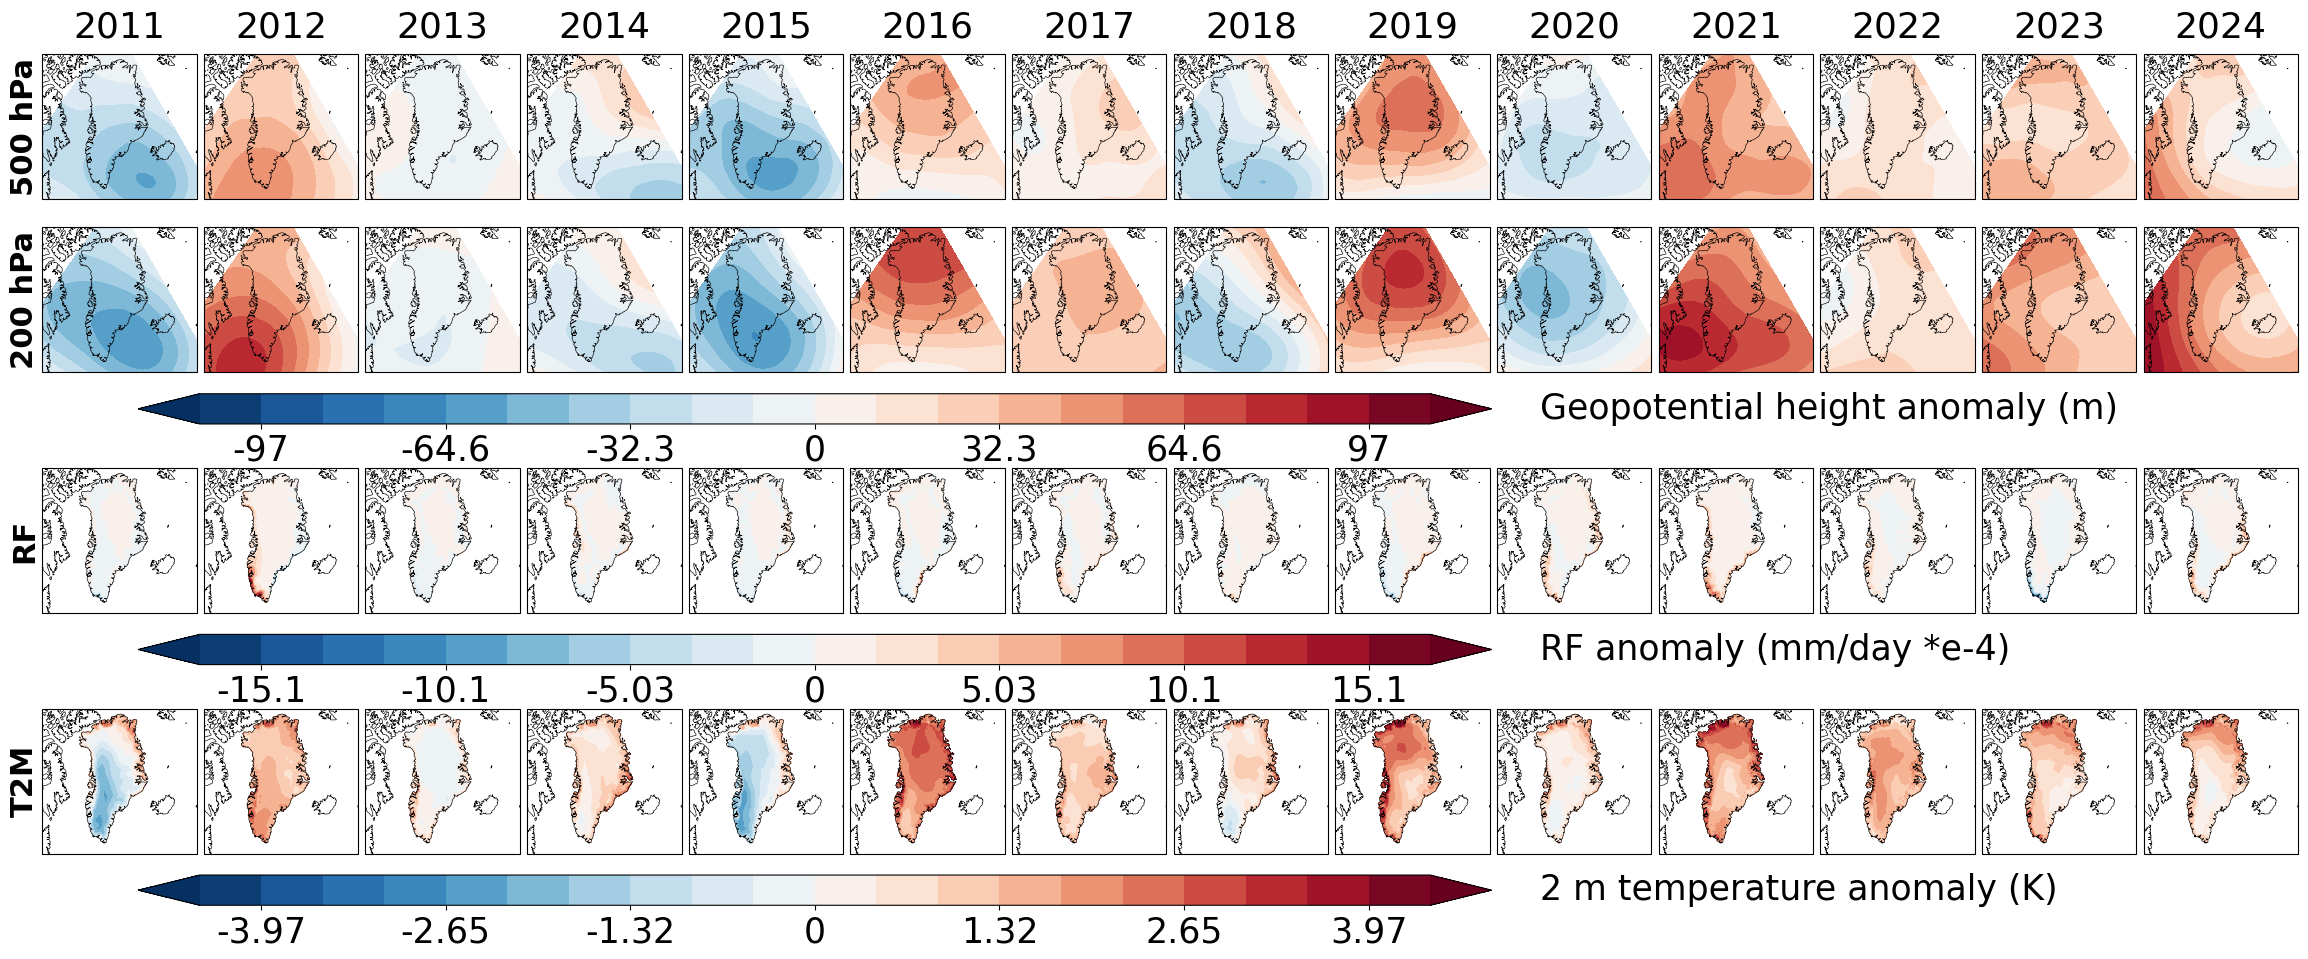

In [2]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ======================= 全局参数 =======================
FONT_SIZE       = 30
ROW_LABEL_SIZE  = 22
YEAR_FONT_SIZE  = 26
CBAR_LABEL_SIZE = 25
CBAR_TICK_SIZE  = 25

ROW_H           = 0.125
ROW_GAP_RATIO   = 0.10
CBAR_H          = 0.024
CBAR_GAP_ABOVE  = 0.012
AFTER_CBAR_GAP  = 0.030

EXTENT = [-65, -12, 58, 84]   # 放大格陵兰区域
CENTRAL_LON = -40
# =======================================================

# ---------- 1) 读取数据 ----------
file_z  = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5pressure500&200pha.nc"
file_rf = r"C:\greenland\sf_tp_rf.nc"
file_t2m= r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"

def open_da_variants(path, var_candidates, scale=1.0):
    ds = xr.open_dataset(path)
    for v in var_candidates:
        if v in ds:
            da = ds[v]; break
    else:
        key = [k for k in ds.data_vars if any(v.lower() in k.lower() for v in var_candidates)]
        if not key:
            raise KeyError(f"No var in {var_candidates}")
        da = ds[key[0]]
    rename = {}
    for d in da.dims:
        dl = d.lower()
        if dl in ["valid_time","time"]: rename[d] = "time"
        if dl in ["lat","latitude"]:    rename[d] = "latitude"
        if dl in ["lon","longitude"]:   rename[d] = "longitude"
    return da.rename(rename) * scale

# geopotential height
ds_z = xr.open_dataset(file_z)
z500 = (ds_z["z"].sel(pressure_level=500) / 9.80665).rename({"valid_time":"time"})
z200 = (ds_z["z"].sel(pressure_level=200) / 9.80665).rename({"valid_time":"time"})
# rainfall & temperature
rf  = open_da_variants(file_rf,  ["rf","rain","rainfall","tp"]) * 1e4
t2m = open_da_variants(file_t2m, ["t2m","2t","t2m_jja_mean"])

# ---------- 2) 距平 ----------
def anomalies_vs_clim(da, years):
    clim = da.mean("time")
    anos = {}
    for y in years:
        try:
            jj = da.sel(time=da["time"].dt.year == y).mean("time")
        except Exception:
            jj = da.sel(time=da["time"].astype(str).str.startswith(str(y))).mean("time")
        anos[y] = jj - clim
    vmax = np.nanmax(np.abs([float(anos[y].max()) for y in anos]))
    return anos, vmax

years = list(range(2011, 2025))
ano500, vmax500 = anomalies_vs_clim(z500, years)
ano200, vmax200 = anomalies_vs_clim(z200, years)
anorf,  vmaxrf  = anomalies_vs_clim(rf,  years)
anot2m, vmaxt2m = anomalies_vs_clim(t2m, years)
vmax_z = max(vmax500, vmax200)

# ---------- 3) 布局 ----------
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
fig  = plt.figure(figsize=(24, 12.6))

left, right = 0.03, 0.97
top, bottom = 0.95, 0.07
N = len(years)
gap_w = 0.003
row_h = ROW_H
gap_v = ROW_H * ROW_GAP_RATIO

total_w = right - left
ax_w = (total_w - gap_w * (N - 1)) / N

# y坐标
y_row1     = top - row_h
y_row2     = y_row1 - gap_v - row_h
y_cbar_z   = y_row2 - CBAR_GAP_ABOVE - CBAR_H
y_row3     = y_cbar_z - AFTER_CBAR_GAP - row_h
y_cbar_rf  = y_row3 - CBAR_GAP_ABOVE - CBAR_H
y_row4     = y_cbar_rf - AFTER_CBAR_GAP - row_h
y_cbar_t2m = y_row4 - CBAR_GAP_ABOVE - CBAR_H

# ---------- 4) 绘制函数 ----------
def plot_row(anodict, vmax, y0, label_text):
    axes_row = []
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    for i, y in enumerate(years):
        x0 = left + i * (ax_w + gap_w)
        ax = fig.add_axes([x0, y0, ax_w, row_h], projection=proj)
        axes_row.append(ax)
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.45)
        ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.25)
        ax.set_xticks([]); ax.set_yticks([])
        cf = ax.contourf(
            anodict[y].longitude, anodict[y].latitude, anodict[y],
            levels=np.linspace(-vmax, vmax, 21),
            cmap="RdBu_r", norm=norm, extend="both", transform=ccrs.PlateCarree()
        )
    axes_row[0].text(-0.02, 0.5, label_text, transform=axes_row[0].transAxes,
                     ha='right', va='center', fontsize=ROW_LABEL_SIZE,
                     weight='bold', rotation=90)
    return axes_row, cf

# 绘制各行
axes_500, cf_500 = plot_row(ano500, vmax_z,   y_row1, "500 hPa")
axes_200, cf_200 = plot_row(ano200, vmax_z,   y_row2, "200 hPa")
axes_rf,  cf_rf  = plot_row(anorf,  vmaxrf,   y_row3, "RF")
axes_t2m,cf_t2m  = plot_row(anot2m, vmaxt2m,  y_row4, "T2M")

# 年份标签
for i, y in enumerate(years):
    bb = axes_500[i].get_position()
    fig.text(bb.x0 + bb.width/2, bb.y1 + 0.008, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

# ---------- 5) 色条 ----------
def add_cbar(cf, y_cbar, label_text):
    cbar_width = (right - left) * 0.60
    cax = fig.add_axes([left + 0.04, y_cbar, cbar_width, CBAR_H])
    cb  = fig.colorbar(cf, cax=cax, orientation="horizontal", format='%.3g')
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)
    label_x = left + 0.04 + cbar_width + 0.02
    fig.text(label_x, y_cbar + CBAR_H/2, label_text,
             fontsize=CBAR_LABEL_SIZE, va='center', ha='left')
    return cb

add_cbar(cf_200, y_cbar_z,   "Geopotential height anomaly (m)")
add_cbar(cf_rf,  y_cbar_rf,  "RF anomaly (mm/day *e-4)")
add_cbar(cf_t2m, y_cbar_t2m, "2 m temperature anomaly (K)")

plt.show()


🚀 格陵兰降雪距平分析 - 简化版
📅 分析窗口: Sep-May
📊 目标年份: 2011-2024
📈 基准期: 1981-2010

📂 [步骤1] 数据读取与快速检查
   变量: ['spatial_ref', 'sf', 'tp', 'rf']
   坐标: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
✅ 使用变量: sf
✅ 时间维: valid_time
✅ 经纬度: longitude, latitude
   时间类型: datetime64[ns]
✅ 时间解码完成: datetime64[ns]

📅 [步骤2] 构建时间窗口
   数据时间范围: 1950-2025
   月份范围: 1-12
✅ 窗口数据比例: 75.0%

📊 [步骤3] 年度数据聚合
✅ 可用年份: 1950-2025 (76年)

📈 [步骤4] 距平计算
   基准期可用年份: 30/30
✅ 基准期气候态计算完成
✅ 距平计算完成: 14 年

📈 [步骤5] 数据统计
   距平范围: [-0.002, 0.002]

🎨 [步骤6] 准备可视化

🖼️  [步骤7] 绘制基准期气候态
✅ 基准期图已保存: C:\greenland\climatology_Sep-May_1981-2010.png

🖼️  [步骤8] 绘制距平面板图
✅ 距平面板图已保存: C:\greenland\anomalies_Sep-May_2011-2024.png


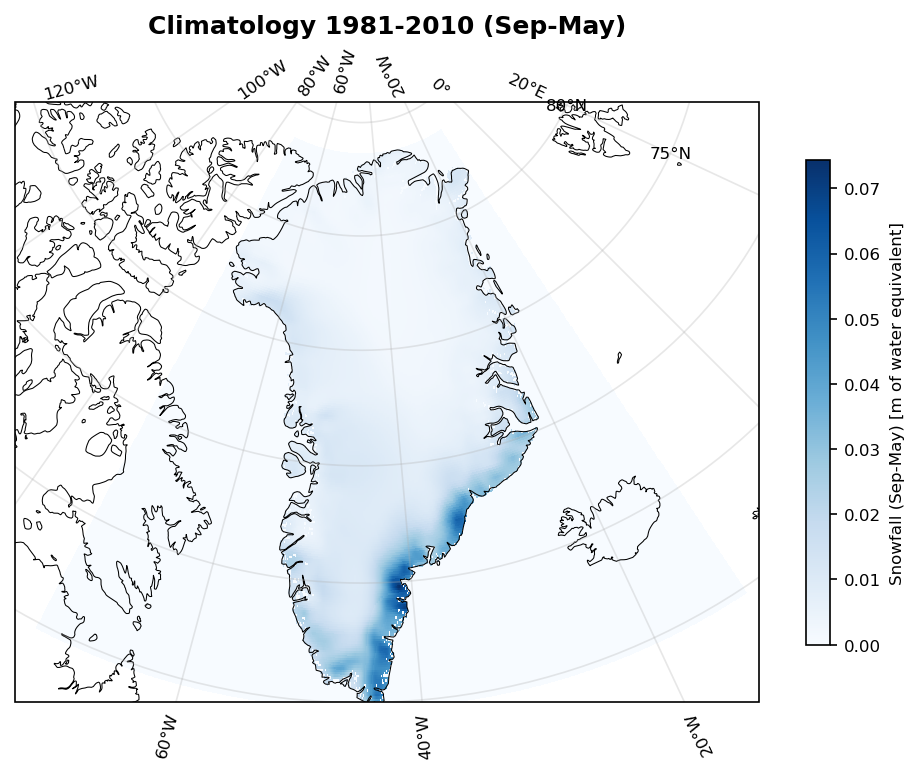

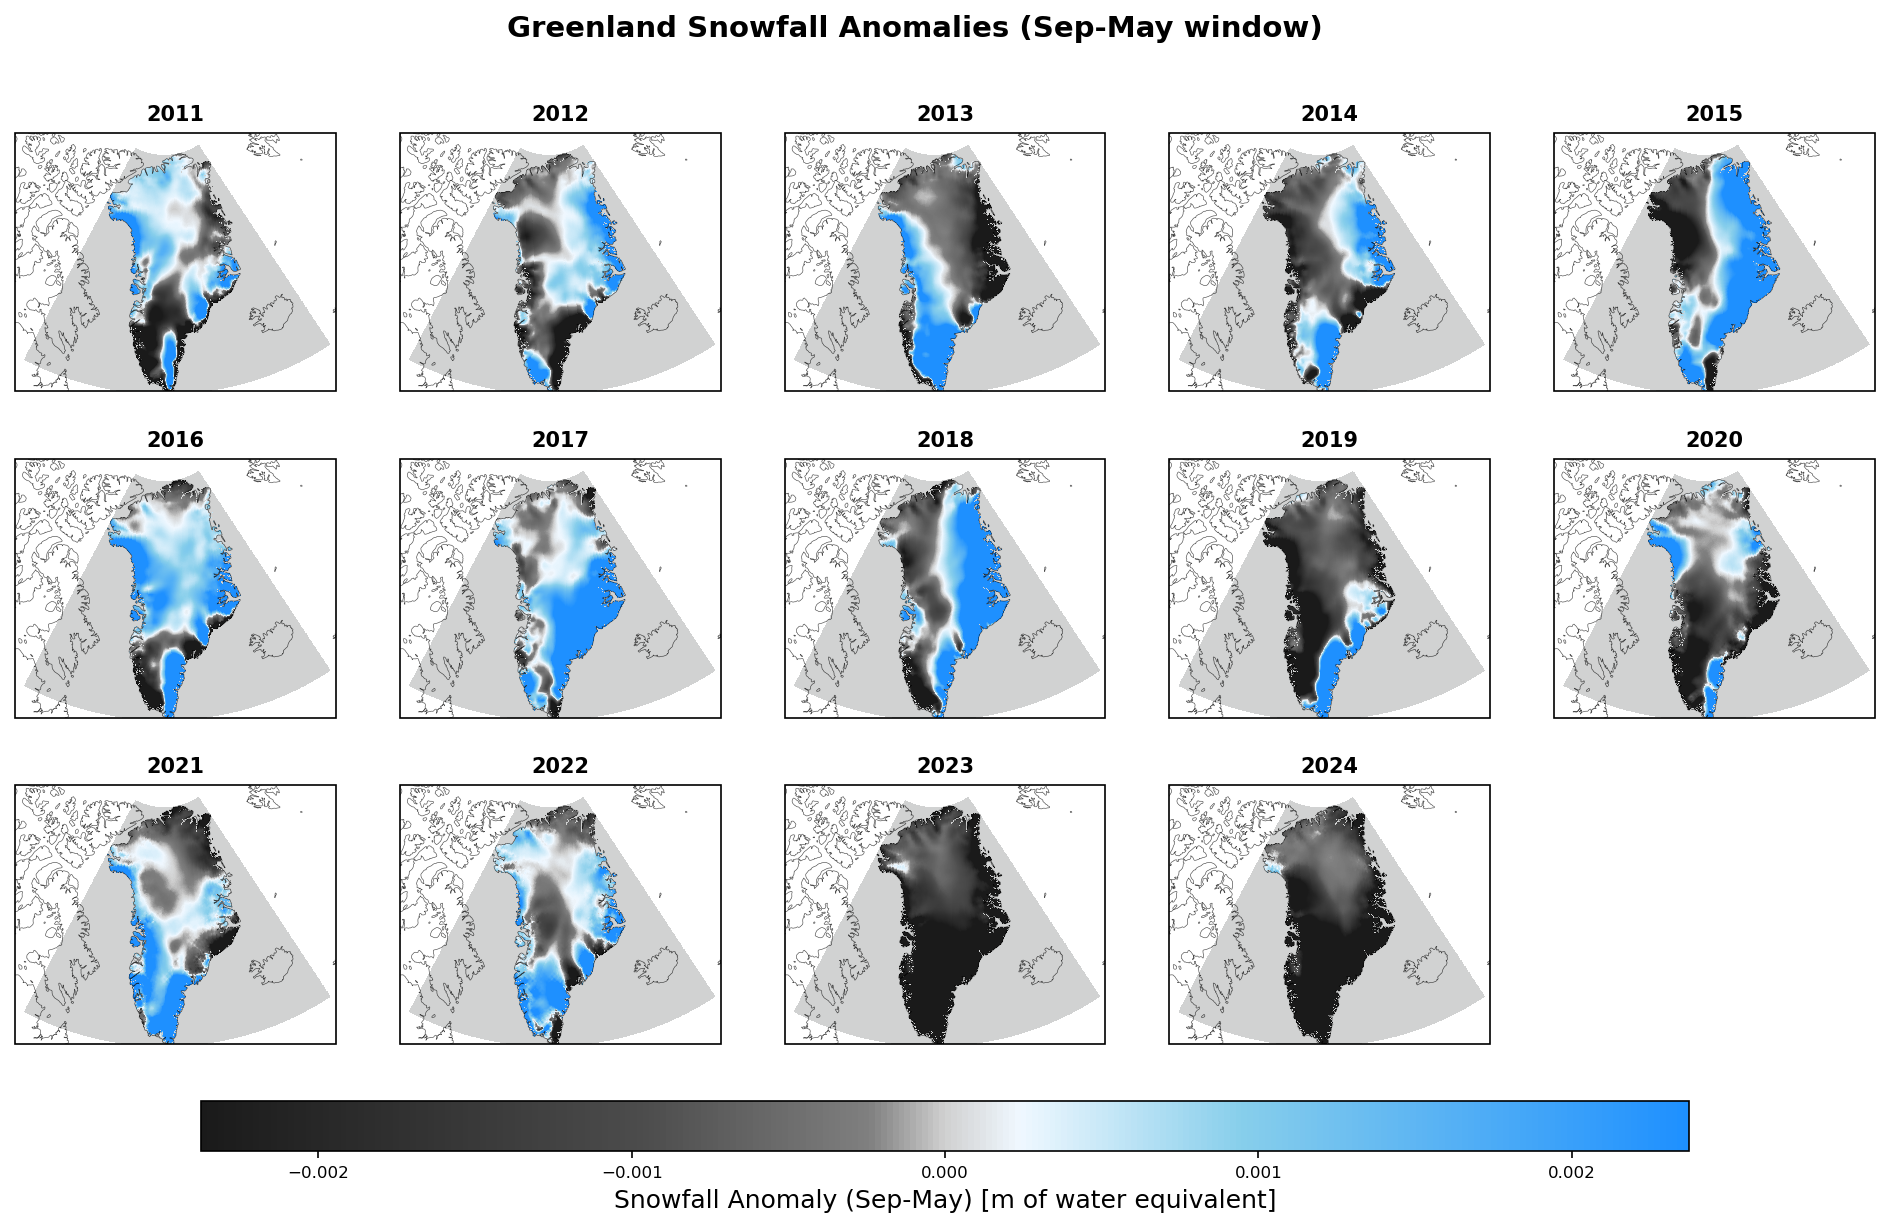


✨ 分析完成!
📁 输出目录: C:\greenland
📊 分析了 14 年的数据
🎯 距平范围: -0.002 ~ 0.002 m of water equivalent
📈 区域趋势: -0.0001 m of water equivalent/year

🎨 颜色说明:
   🖤 深灰/黑色 = 降雪显著减少
   🔘 浅灰色 = 接近正常水平
   🔵 蓝色 = 降雪增加
   ⚪ 白色/浅蓝 = 降雪显著增加


In [11]:
# -*- coding: utf-8 -*-
"""
格陵兰降雪距平分析 - 简化版
重点：快速查看降雪距平模式，无shp裁剪，直接可视化
"""

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# ==================== 参数设置 ====================
print("🚀 格陵兰降雪距平分析 - 简化版")
nc_path = r"C:\greenland\sf_tp_rf.nc"
outdir = os.path.dirname(nc_path) or "."

# 时间窗口设置
WINDOW = 'Sep-May'  # 可选: 'Oct-May', 'Nov-May', 'AM', 'AMJ'
years = list(range(2011, 2024 + 1))  # 分析年份
BASE_RANGE = (1981, 2010)  # 基准期

# 地图设置
proj = ccrs.NorthPolarStereo(central_longitude=-45)
pc = ccrs.PlateCarree()
extent = [-75, -10, 60, 85]  # 格陵兰区域

print(f"📅 分析窗口: {WINDOW}")
print(f"📊 目标年份: {years[0]}-{years[-1]}")
print(f"📈 基准期: {BASE_RANGE[0]}-{BASE_RANGE[1]}")

# ==================== 数据读取与检查 ====================
print("\n📂 [步骤1] 数据读取与快速检查")

if not os.path.exists(nc_path):
    raise FileNotFoundError(f"文件不存在: {nc_path}")

# 读取数据
ds = xr.open_dataset(nc_path)
print(f"   变量: {list(ds.data_vars)}")
print(f"   坐标: {list(ds.coords)}")

# 选择变量
var_name = 'sf' if 'sf' in ds.data_vars else list(ds.data_vars)[0]
da = ds[var_name]
print(f"✅ 使用变量: {var_name}")

# 检查时间维
time_dim = None
for t in ['valid_time', 'time']:
    if t in da.dims:
        time_dim = t
        break

if time_dim is None:
    print(f"❌ 找不到时间维，可用维度: {list(da.dims)}")
    raise ValueError("未找到时间维")

print(f"✅ 时间维: {time_dim}")

# 检查空间坐标  
lon_name = next((n for n in ['longitude', 'lon', 'x'] if n in da.coords), None)
lat_name = next((n for n in ['latitude', 'lat', 'y'] if n in da.coords), None)

if lon_name is None or lat_name is None:
    print(f"❌ 找不到经纬度，可用坐标: {list(da.coords)}")
    raise ValueError("未找到经纬度坐标")

print(f"✅ 经纬度: {lon_name}, {lat_name}")

# 时间处理
time_coord = da[time_dim]
print(f"   时间类型: {time_coord.dtype}")

# 自动时间解码
if not np.issubdtype(time_coord.dtype, np.datetime64):
    print("   执行时间解码...")
    ds = xr.decode_cf(ds)
    da = ds[var_name]
    time_coord = da[time_dim]

print(f"✅ 时间解码完成: {time_coord.dtype}")

# ==================== 时间窗口定义 ====================
print("\n📅 [步骤2] 构建时间窗口")

# 提取时间信息
months = time_coord.dt.month.values
years_data = time_coord.dt.year.values

print(f"   数据时间范围: {years_data.min()}-{years_data.max()}")
print(f"   月份范围: {months.min()}-{months.max()}")

# 定义窗口规则
def get_window_mask(months, years_data, window):
    """根据窗口类型返回掩膜"""
    if window == 'Sep-May':
        # Sep-May: 9月属于下一年，10-12月属于下一年，1-5月属于当年
        target_year = np.where(months == 9, years_data + 1,
                      np.where(np.isin(months, [10,11,12]), years_data + 1,
                      np.where(np.isin(months, [1,2,3,4,5]), years_data, np.nan)))
    elif window == 'Oct-May':
        target_year = np.where(np.isin(months, [10,11,12]), years_data + 1,
                      np.where(np.isin(months, [1,2,3,4,5]), years_data, np.nan))
    elif window == 'Nov-May':
        target_year = np.where(np.isin(months, [11,12]), years_data + 1,
                      np.where(np.isin(months, [1,2,3,4,5]), years_data, np.nan))
    elif window == 'AM':  # April-May
        target_year = np.where(np.isin(months, [4,5]), years_data, np.nan)
    elif window == 'AMJ':  # April-May-June
        target_year = np.where(np.isin(months, [4,5,6]), years_data, np.nan)
    else:
        raise ValueError(f"未知窗口: {window}")
    
    return target_year

target_years = get_window_mask(months, years_data, WINDOW)
valid_mask = ~np.isnan(target_years)

print(f"✅ 窗口数据比例: {valid_mask.sum() / len(valid_mask):.1%}")

# 筛选数据
da_windowed = da.isel({time_dim: valid_mask})
target_years_valid = target_years[valid_mask]

# ==================== 年度聚合 ====================
print("\n📊 [步骤3] 年度数据聚合")

# 创建年度分组数据
time_grouped = xr.DataArray(target_years_valid, 
                           dims=[time_dim], 
                           coords={time_dim: da_windowed[time_dim]})

# 按年聚合
yearly_data = da_windowed.groupby(time_grouped).sum()
yearly_data = yearly_data.rename(group='year')

available_years = yearly_data.year.values.astype(int)
print(f"✅ 可用年份: {available_years.min()}-{available_years.max()} ({len(available_years)}年)")

# ==================== 基准期和距平计算 ====================
print("\n📈 [步骤4] 距平计算")

# 基准期数据
base_years_list = list(range(BASE_RANGE[0], BASE_RANGE[1] + 1))
base_available = [y for y in base_years_list if y in available_years]

print(f"   基准期可用年份: {len(base_available)}/{len(base_years_list)}")

if len(base_available) < 5:
    print("⚠️ 基准期数据较少，结果可能不稳定")

# 计算基准期气候态
base_data = yearly_data.sel(year=base_available)
climatology = base_data.mean(dim='year')

print(f"✅ 基准期气候态计算完成")

# 计算距平
anomalies = {}
for year in years:
    if year in available_years:
        anomalies[year] = yearly_data.sel(year=year) - climatology
    else:
        # 创建NaN数组
        anomalies[year] = xr.full_like(climatology, np.nan)

print(f"✅ 距平计算完成: {len(anomalies)} 年")

# ==================== 数据统计 ====================
print("\n📈 [步骤5] 数据统计")

# 统计距平范围
all_anomaly_values = []
for year, anom in anomalies.items():
    if year in available_years:
        values = anom.values.flatten()
        values = values[np.isfinite(values)]
        all_anomaly_values.extend(values)

if len(all_anomaly_values) > 0:
    anom_array = np.array(all_anomaly_values)
    p5, p95 = np.percentile(anom_array, [5, 95])
    vmax = max(abs(p5), abs(p95)) * 1.1  # 对称范围
    vmin = -vmax
else:
    vmin, vmax = -1, 1

print(f"   距平范围: [{vmin:.3f}, {vmax:.3f}]")

# ==================== 可视化设置 ====================
print("\n🎨 [步骤6] 准备可视化")

# 颜色方案：负(灰黑) → 零(浅灰) → 正(白蓝)
colors = LinearSegmentedColormap.from_list(
    "snowfall_anomaly",
    [(0.0, "#1a1a1a"),   # 深黑 - 大幅减少
     (0.3, "#4d4d4d"),   # 深灰
     (0.45, "#808080"),  # 中灰  
     (0.5, "#d0d0d0"),   # 浅灰 - 接近零
     (0.55, "#f0f8ff"),  # 爱丽丝蓝
     (0.7, "#87ceeb"),   # 天空蓝
     (1.0, "#1e90ff")]   # 道奇蓝 - 大幅增加
)

norm = TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax)

# 绘图参数
plt.rcParams.update({
    'font.size': 8,
    'figure.dpi': 150,
    'savefig.bbox': 'tight'
})

# ==================== 绘制基准期气候态 ====================
print("\n🖼️  [步骤7] 绘制基准期气候态")

fig1, ax1 = plt.subplots(1, 1, figsize=(8, 6), 
                         subplot_kw={'projection': proj})

ax1.set_extent(extent, crs=pc)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.add_feature(cfeature.BORDERS, linewidth=0.3)
ax1.gridlines(draw_labels=True, alpha=0.3)

# 绘制数据
lon_vals = climatology[lon_name].values  
lat_vals = climatology[lat_name].values
clim_vals = climatology.values

if lon_vals.ndim == 1 and lat_vals.ndim == 1:
    lon_2d, lat_2d = np.meshgrid(lon_vals, lat_vals)
else:
    lon_2d, lat_2d = lon_vals, lat_vals

im1 = ax1.pcolormesh(lon_2d, lat_2d, clim_vals, 
                     transform=pc, cmap='Blues', shading='auto')

cbar1 = plt.colorbar(im1, ax=ax1, shrink=0.7)
unit_str = da.attrs.get('units', 'units')
cbar1.set_label(f'Snowfall ({WINDOW}) [{unit_str}]')

ax1.set_title(f'Climatology {BASE_RANGE[0]}-{BASE_RANGE[1]} ({WINDOW})', 
              fontsize=12, fontweight='bold')

# 保存
fig1_path = os.path.join(outdir, f'climatology_{WINDOW}_{BASE_RANGE[0]}-{BASE_RANGE[1]}.png')
fig1.savefig(fig1_path, dpi=200)
print(f"✅ 基准期图已保存: {fig1_path}")

# ==================== 绘制距平面板图 ====================
print("\n🖼️  [步骤8] 绘制距平面板图")

# 3x5 布局
nrows, ncols = 3, 5
fig2, axes = plt.subplots(nrows, ncols, figsize=(16, 10),
                          subplot_kw={'projection': proj})
axes = axes.flatten()

for i, year in enumerate(years):
    ax = axes[i]
    ax.set_extent(extent, crs=pc)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.3, alpha=0.7)
    
    # 绘制距平
    if year in available_years:
        anom_vals = anomalies[year].values
        im = ax.pcolormesh(lon_2d, lat_2d, anom_vals,
                          transform=pc, cmap=colors, norm=norm, 
                          shading='auto')
        title_color = 'black'
    else:
        # 无数据年份显示空白
        ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes,
               ha='center', va='center', fontsize=10, alpha=0.5)
        title_color = 'gray'
    
    ax.set_title(f'{year}', fontsize=10, fontweight='bold', color=title_color)
    ax.set_xticks([])
    ax.set_yticks([])

# 移除多余的子图
for j in range(len(years), len(axes)):
    axes[j].remove()

# 添加共享色标
cbar2 = fig2.colorbar(im, ax=axes[:len(years)], shrink=0.8, 
                      orientation='horizontal', pad=0.05, aspect=30)
cbar2.set_label(f'Snowfall Anomaly ({WINDOW}) [{unit_str}]', fontsize=12)

fig2.suptitle(f'Greenland Snowfall Anomalies ({WINDOW} window)', 
              fontsize=14, fontweight='bold', y=0.95)

# 保存
fig2_path = os.path.join(outdir, f'anomalies_{WINDOW}_{years[0]}-{years[-1]}.png')
fig2.savefig(fig2_path, dpi=200)
print(f"✅ 距平面板图已保存: {fig2_path}")

plt.show()

# ==================== 结果总结 ====================
print("\n✨ 分析完成!")
print(f"📁 输出目录: {outdir}")
print(f"📊 分析了 {len([y for y in years if y in available_years])} 年的数据")
print(f"🎯 距平范围: {vmin:.3f} ~ {vmax:.3f} {unit_str}")

# 简单趋势分析
valid_years_list = [y for y in years if y in available_years]
if len(valid_years_list) > 5:
    # 计算区域平均距平
    regional_anomalies = []
    for year in valid_years_list:
        anom = anomalies[year].values
        regional_mean = np.nanmean(anom)
        regional_anomalies.append(regional_mean)
    
    # 简单线性趋势
    if len(regional_anomalies) > 3:
        trend = np.polyfit(valid_years_list, regional_anomalies, 1)[0]
        print(f"📈 区域趋势: {trend:.4f} {unit_str}/year")
        
print("\n🎨 颜色说明:")
print("   🖤 深灰/黑色 = 降雪显著减少")  
print("   🔘 浅灰色 = 接近正常水平")
print("   🔵 蓝色 = 降雪增加")
print("   ⚪ 白色/浅蓝 = 降雪显著增加")